In [ ]:
%load_ext autoreload
%autoreload 2

import astropy.units as u
import matplotlib.pyplot as plt

import src.halo_dynamics as a
import src.subhalo_statistics as b

plt.style.use("src/nicefigures.mplstyle")
OUTPUT = "figures"

## A: Dynamical Analysis of a DM Halo

In [ ]:
data_path = "data/cutout_188106.hdf5"

### Spherical Potential

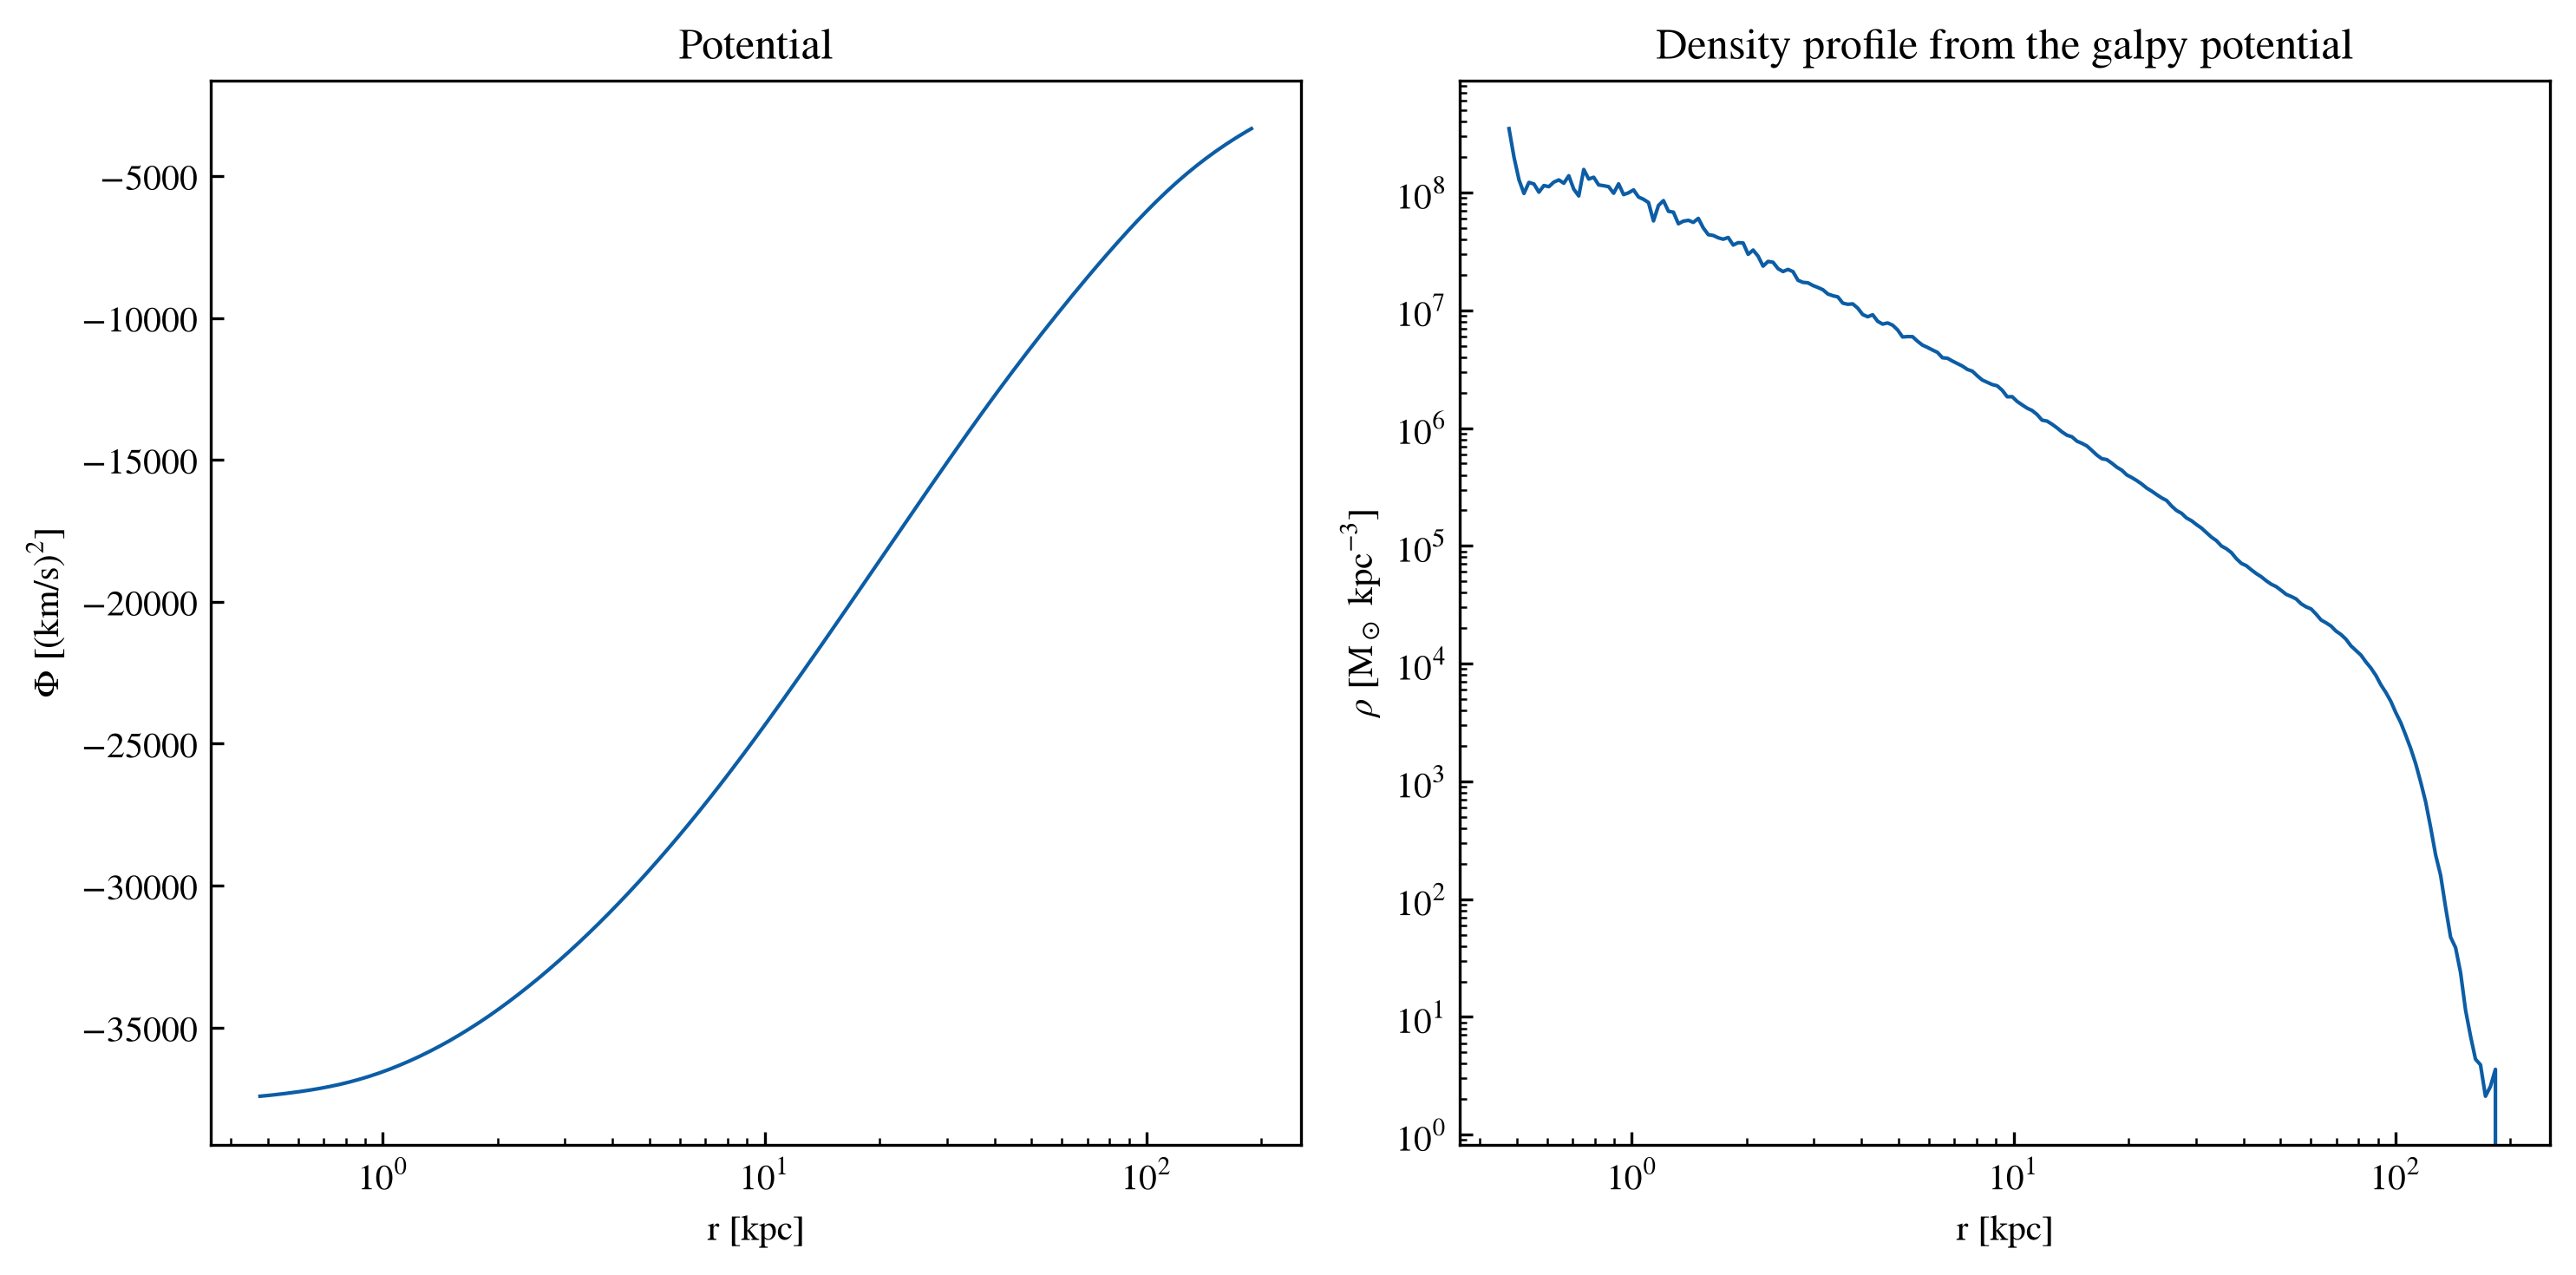

In [ ]:
a.spherical_potential_plotter(data_path, plot=True, output=f"{OUTPUT}/halo_potential_density.png");

Above the potential and the density derived from the particle data (or derived from the galpy model built on the particle data) can be seen. The potential was built under the assumption of a spherically symmetric system/halo, the validity of this assumption is checked later. It can directly be noticed that the density on small length scales is much noisier than the center of the radius interval. This is due to the method by which it was built. The mass was constructed from inside out by adding more and more particles to the total mass in the center, at the small length scales this means every included particle can cause a big jump in the mass/density. To reduce this noise the first few radius bins are omitted from the data shown here. If this isn't done the fitting later on would be less reliable.

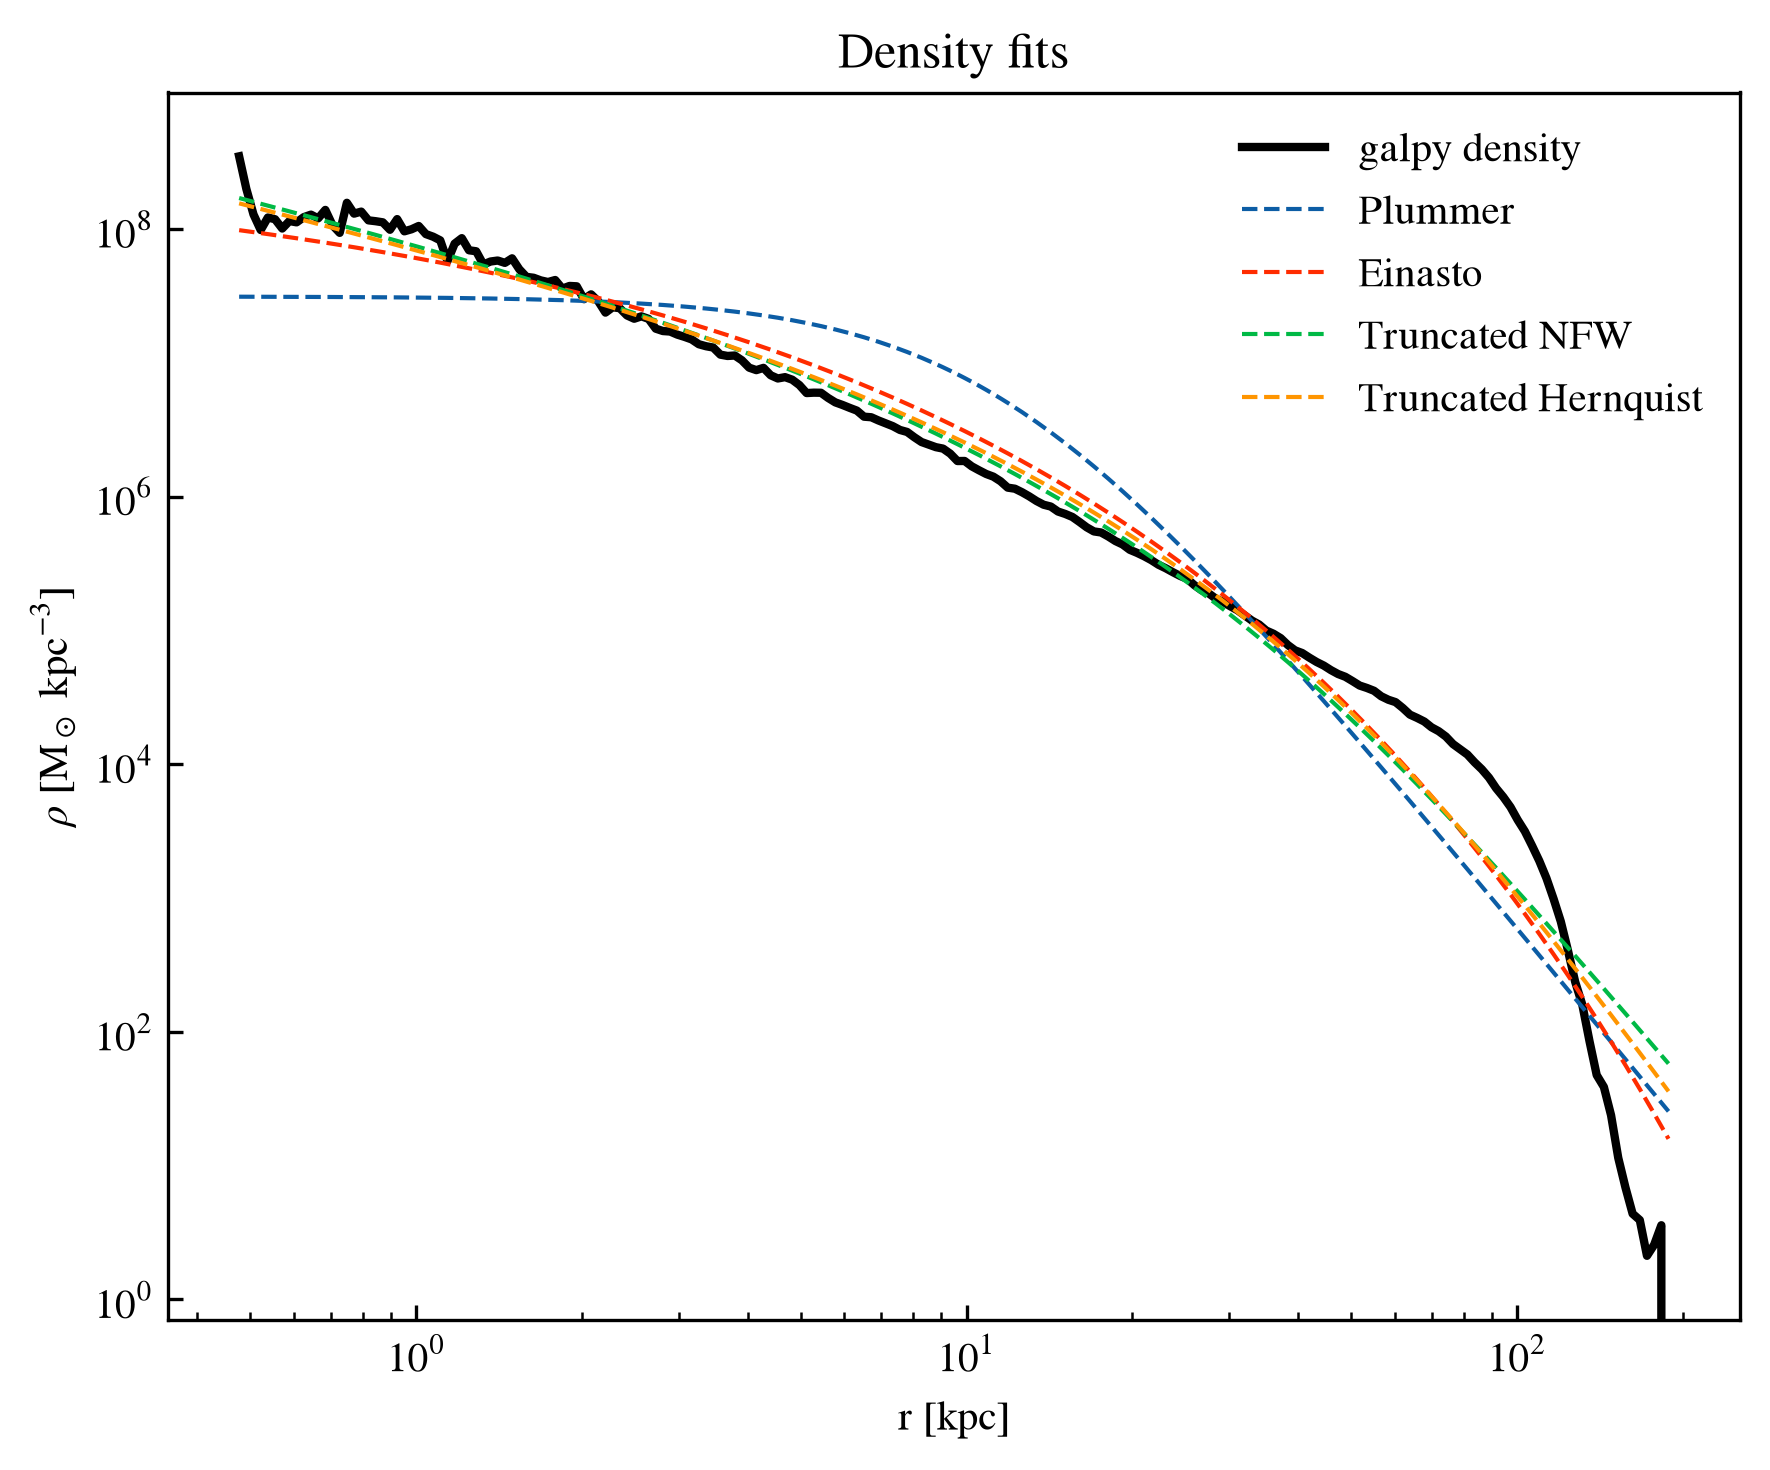

In [ ]:
a.data_fitter(data_path, plot=True, output=f"{OUTPUT}/halo_density_fit.png");

Now a number of spherically symmetric models can be fitted to the density curve, these are:

- Plummer model
- Einasto model
- Truncated NFW model
- Truncated Hernquist model

These four were chosen for different reasons: Einasto and NFW were chosen because they were mentioned in the course notes in the section on the density profile for DM halos, this seemed like a good start. Hernquist and Plummer were chosen because they were mentioned in the section specifically on spherical potentials. In the galpy documentation we found the truncated versions of NFW and Hernquist, this seemed like a better fit to a realistic simulation/data. The goodness of fit was simply tested by the rms deviation between the fitted model and the data, the Einasto model had the smallest rms value so it was chosen as the best model. This agrees with what we learned during the theory lectures.

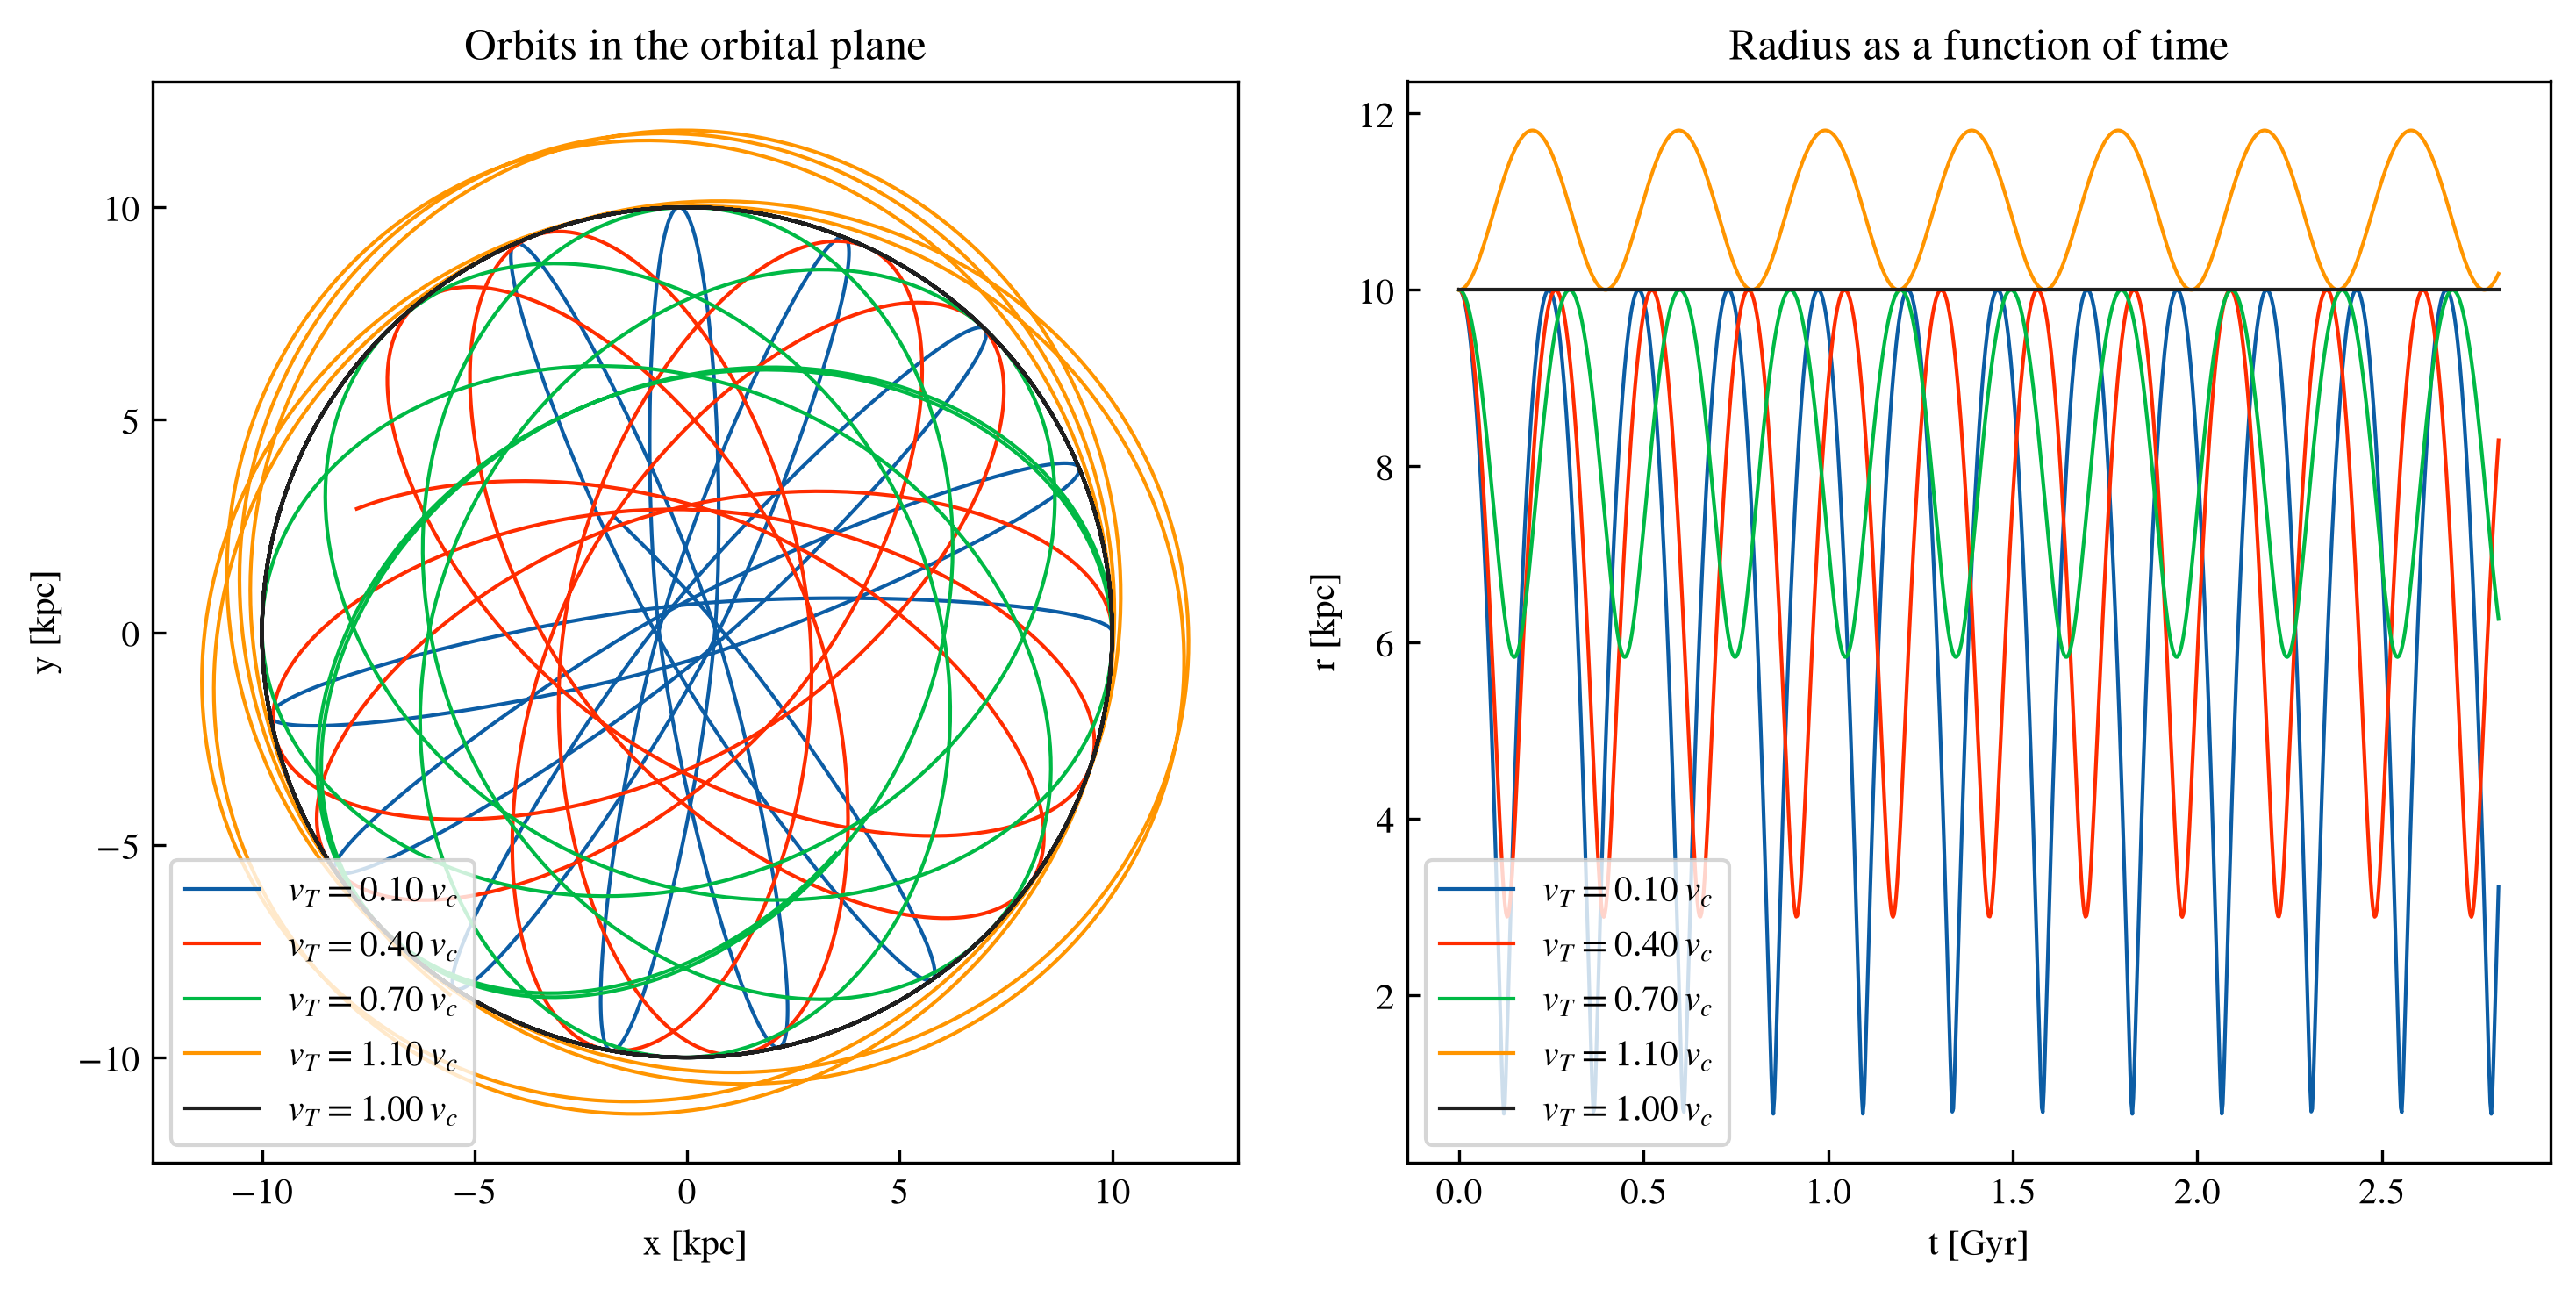

In [ ]:
pot_einasto, rho_einasto, r = a.build_Einasto(data_path)
a.integrate_orbits(pot_einasto, r0=10 * u.kpc, f_vc=(0.1, 0.4, 0.7, 1.1, 1.0), plot=True, output=f"{OUTPUT}/dm_orbits_einasto.png");

Above certain orbits in the Einasto potential can be seen, the typical rosettes of a spherical system can easily be recognized. This obviously matches the expectation.

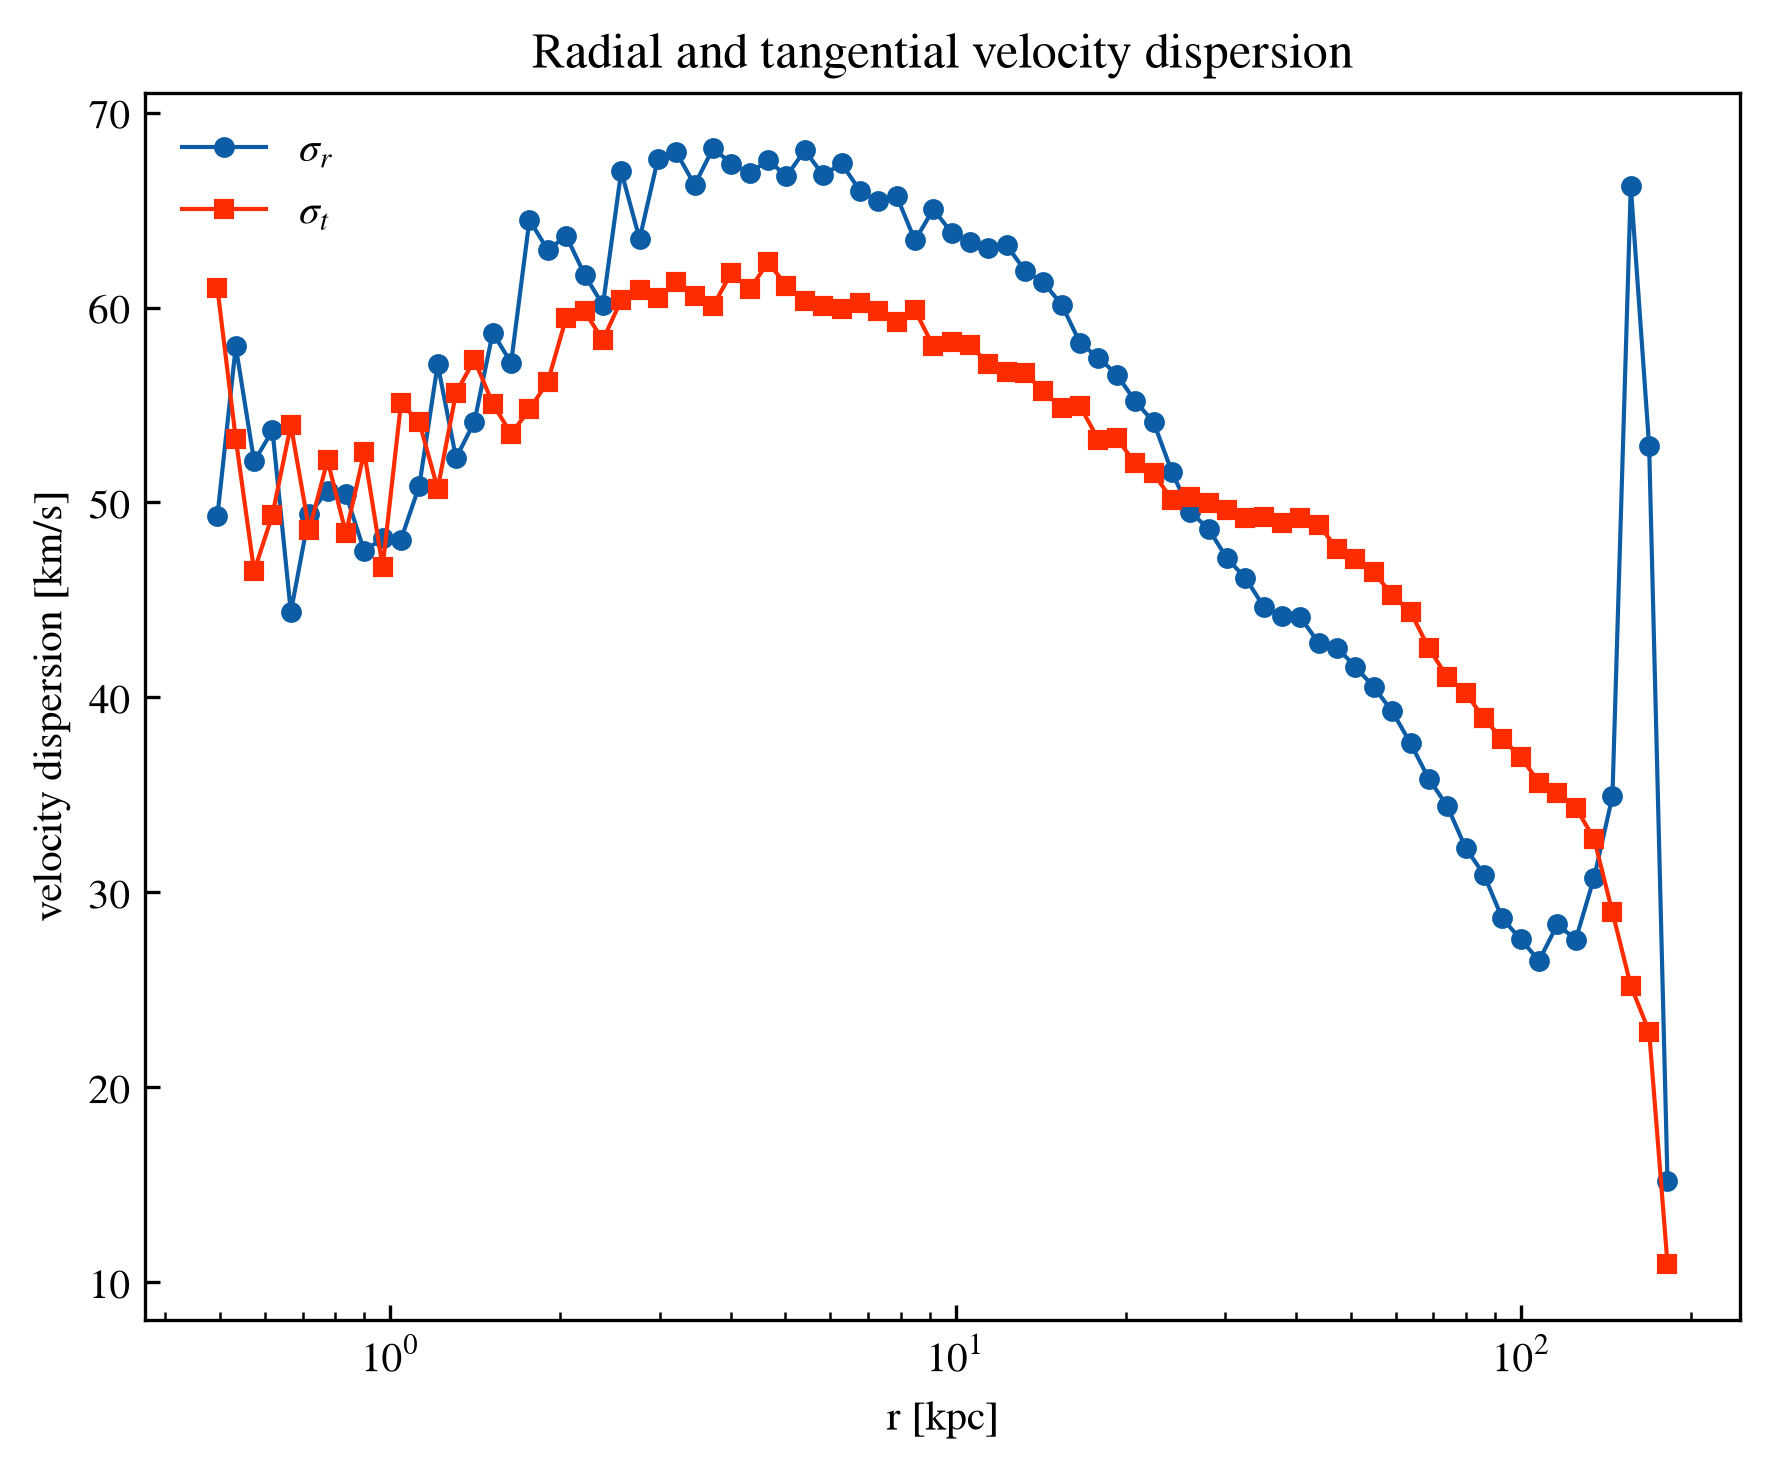

In [ ]:
a.velocity_dispersions(data_path, n_bins=80, plot=True, output=f"{OUTPUT}/dm_dispersions.png");

Here the velocity dispersion in the radial and tangential direction can be seen, they were extracted directly from the particle data and not the fitted Einasto model. Again due to noise concerns the start of the graph was omitted from the data. Near the largest length scales there is also a *very* noticeable random jump in the data, this is because at these large distances there's very little data in each radius/distance bin. Note that because the dispersions were calculated directly from the data this graph doesn't suffer from the assumption of spherical symmetry.

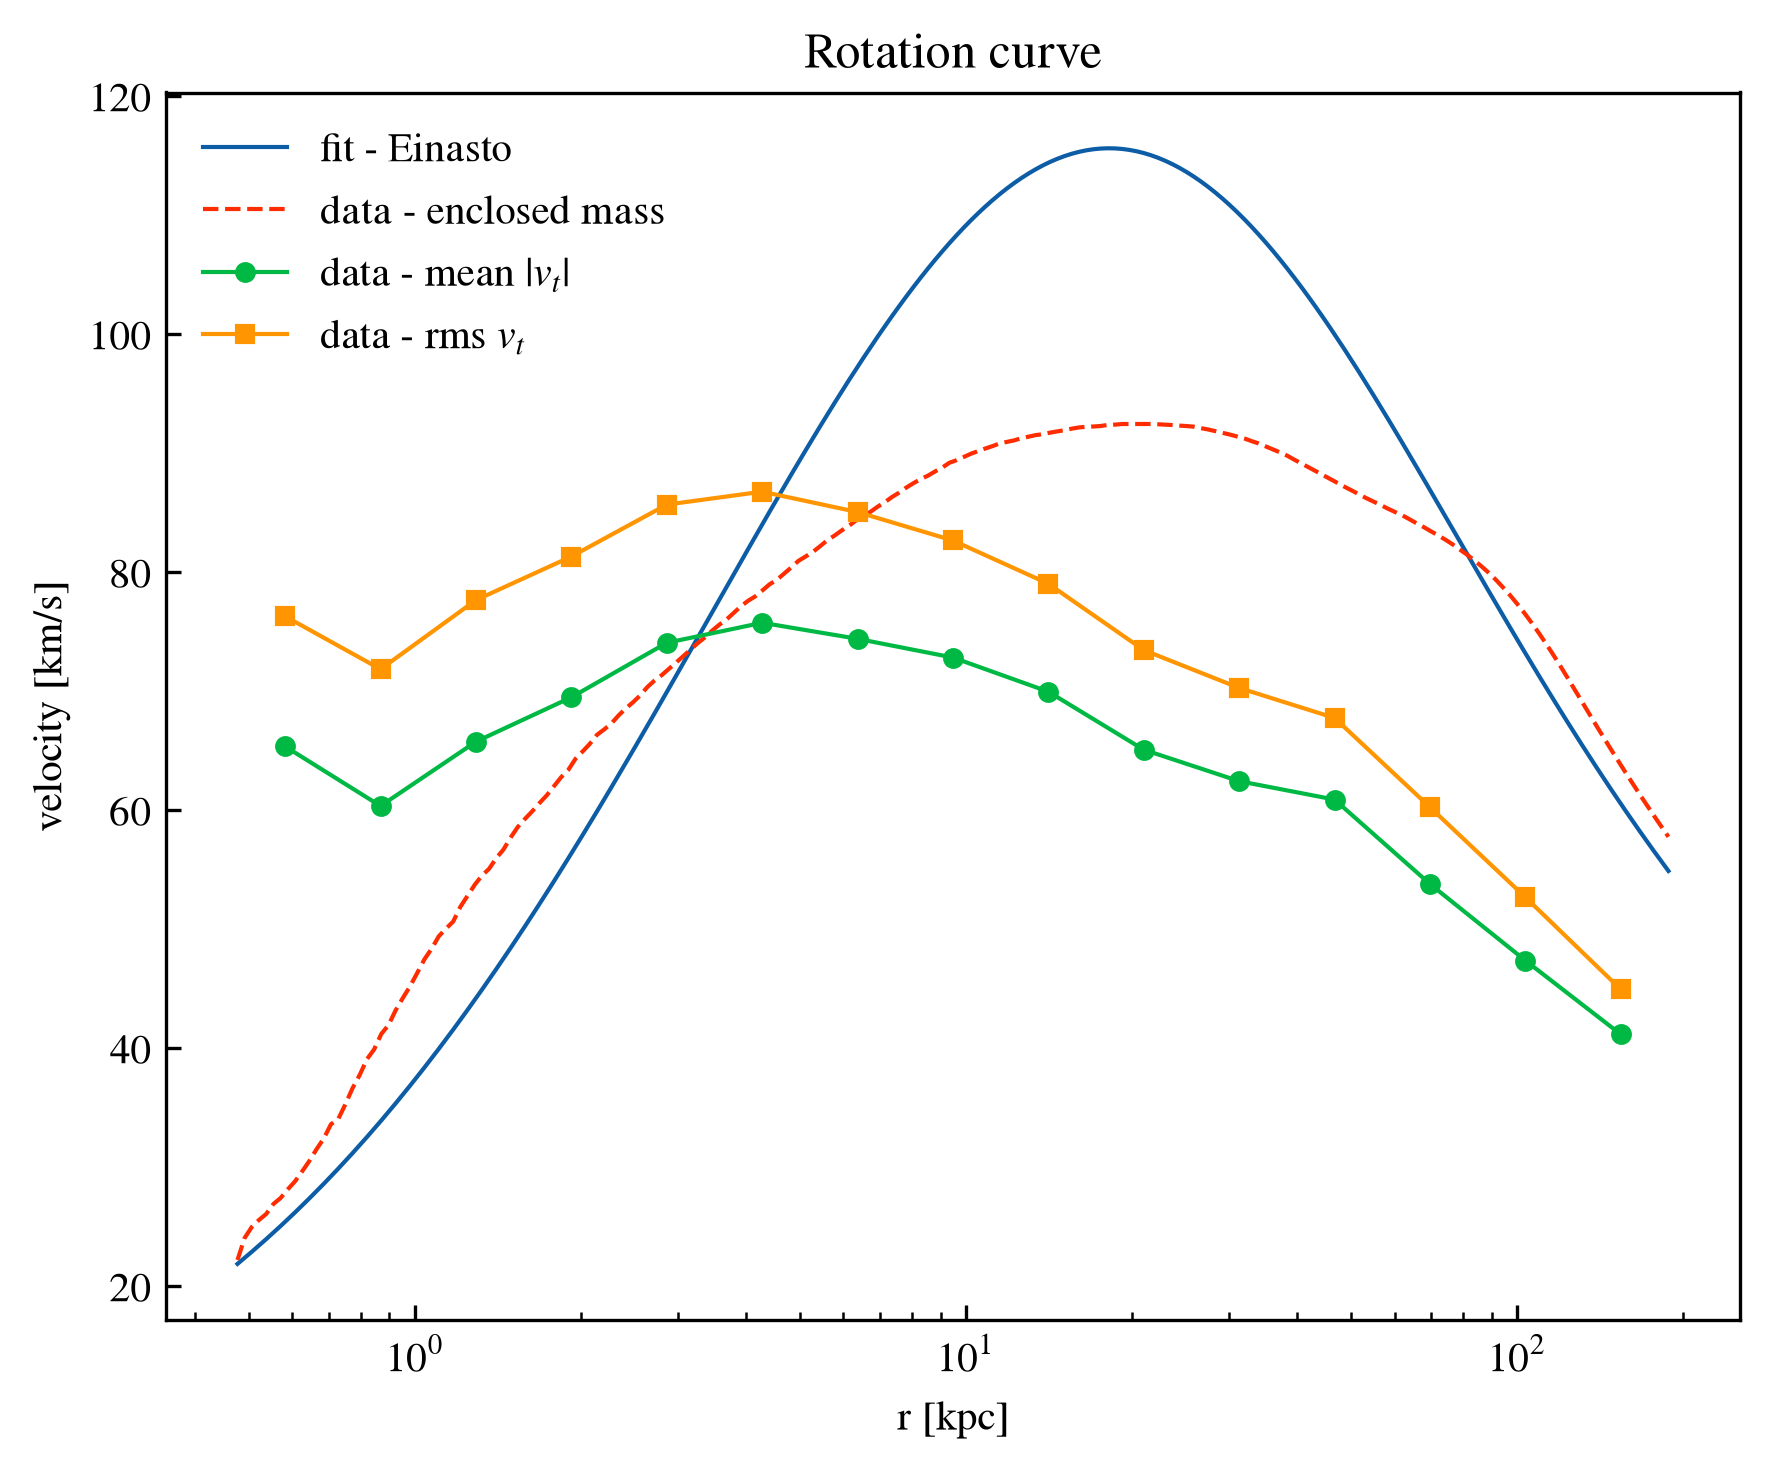

In [ ]:
a.compare_rotation_curves(data_path, plot=True, output=f"{OUTPUT}/dm_circular_velocities.png");

Here the rotation curve can be seen as computed by the three different methods:

- From the galpy function vcirc
- From the enclosed mass
- Directly from the kinematic particle data

It can directly be seen that there is a big discrepancy between all curves. The big difference between the fit and the enclosed mass is most likely due to the inaccuracy of the assumption of spherical symmetry. The fact that the tangential velocity of the actual particles is very different from the other data is because in the average DM halo there is very little actual rotation (DM halos have a very low spin parameter). Most of the energy is in the random motions i.e. the dispersion. 

### Asymmetric Potential

/home/lservaes/miniforge3/envs/tana/lib/python3.14/site-packages/galpy/potential/SCFPotential.py:1202: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  out = numpy.divide((r / a - 1.0), (r / a + 1.0), where=True ^ numpy.isinf(r))



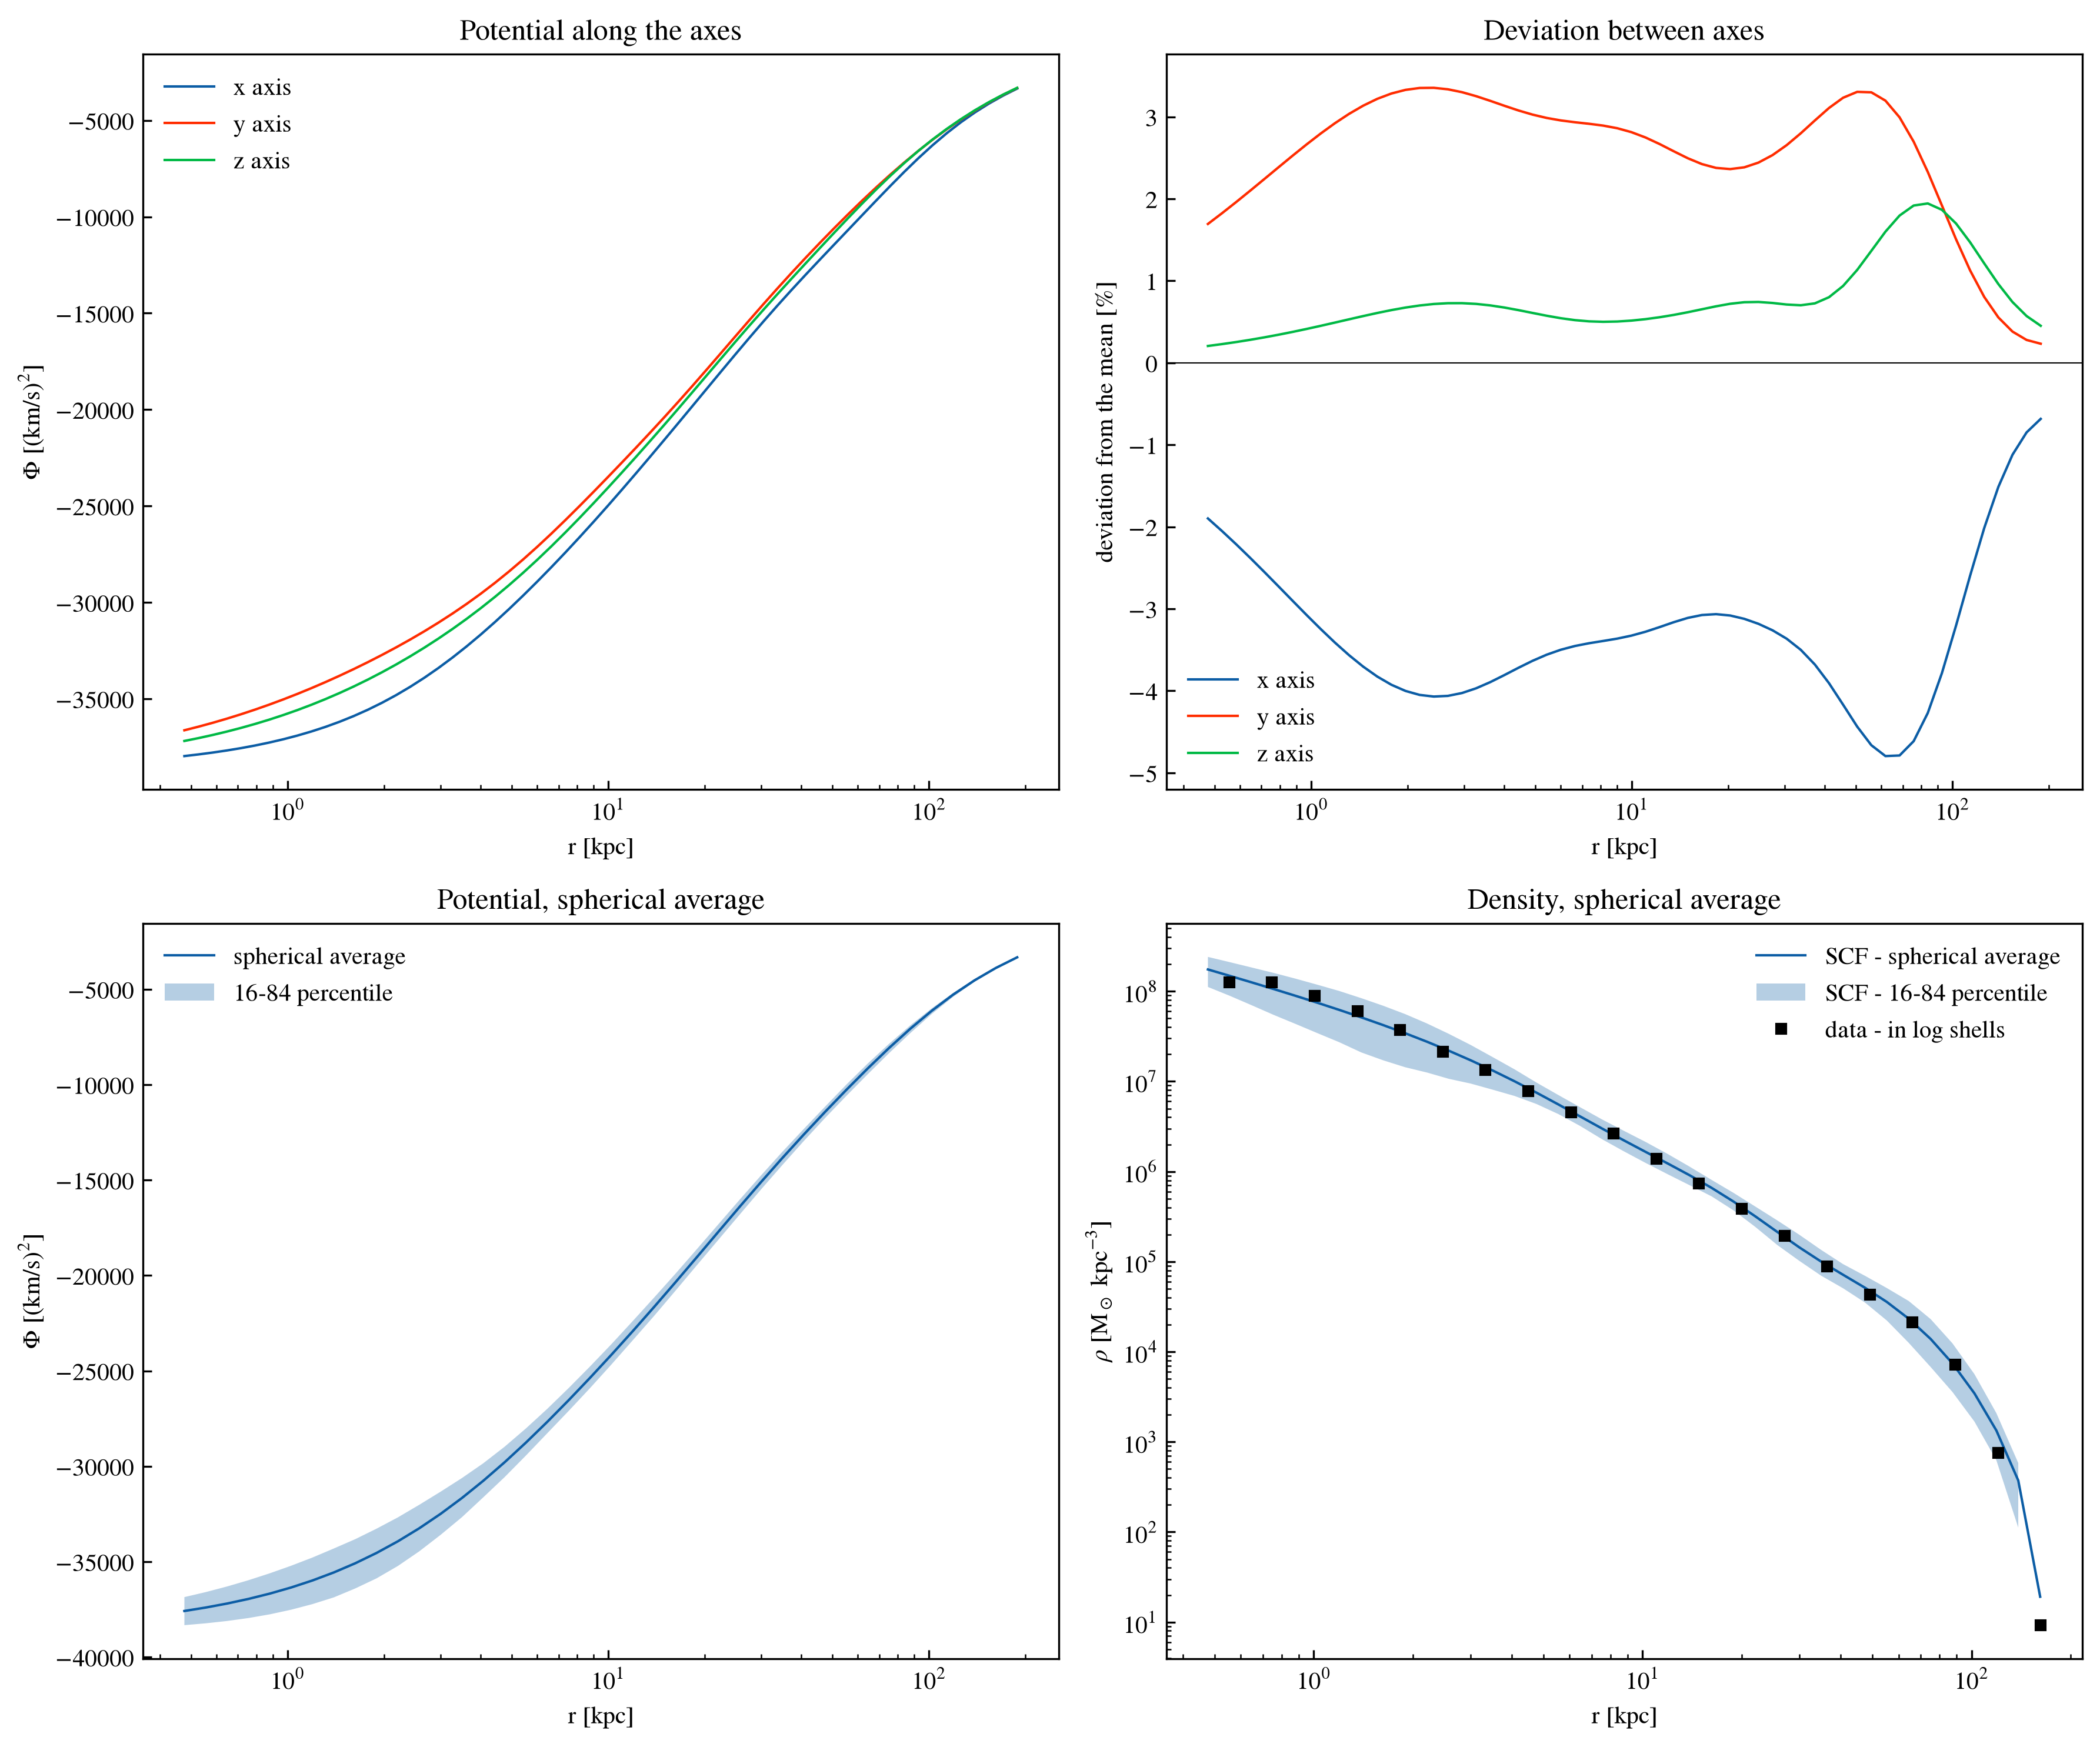

In [ ]:
pot_scf, _ = a.build_scf(data_path, plot=True, output=f"{OUTPUT}/halo_potential_density_scf.png");

In the upper plots above the assumption of spherical symmetry can be checked. The potential is plotted along three different directions and compared. A noticeable anisotropy is immediately observed. In the lower plots the potential and density built from the particle data can be seen averaged over the angular coordinate so a graph is obtained that can be compared to the spherically symmetric case. The spread of this data is represented by the blue area around the curve, it represents the central 68% (the difference between the 84th and 16th percentile of the data) of the data. If this spread/distribution is Gaussian this corresponds to the 1 $\sigma$ level. We opted for this kind of spread because it's not certain this underlying spread is Gaussian.

The actual potential was built by galpy's SCFPotential, this is an expansion and using it requires an assumption or choice as to how many terms should be kept in the expansion. To check our choice was correct the density was calculated and compared to the density calculated based on the model. This seemed like a more efficient idea than fitting a whole host of models.

/home/lservaes/ugent/tana/project/src/halo_dynamics.py:877: RuntimeWarning: invalid value encountered in log10
  cf = a.contourf(g, g, np.log10(rho_map), levels=20)



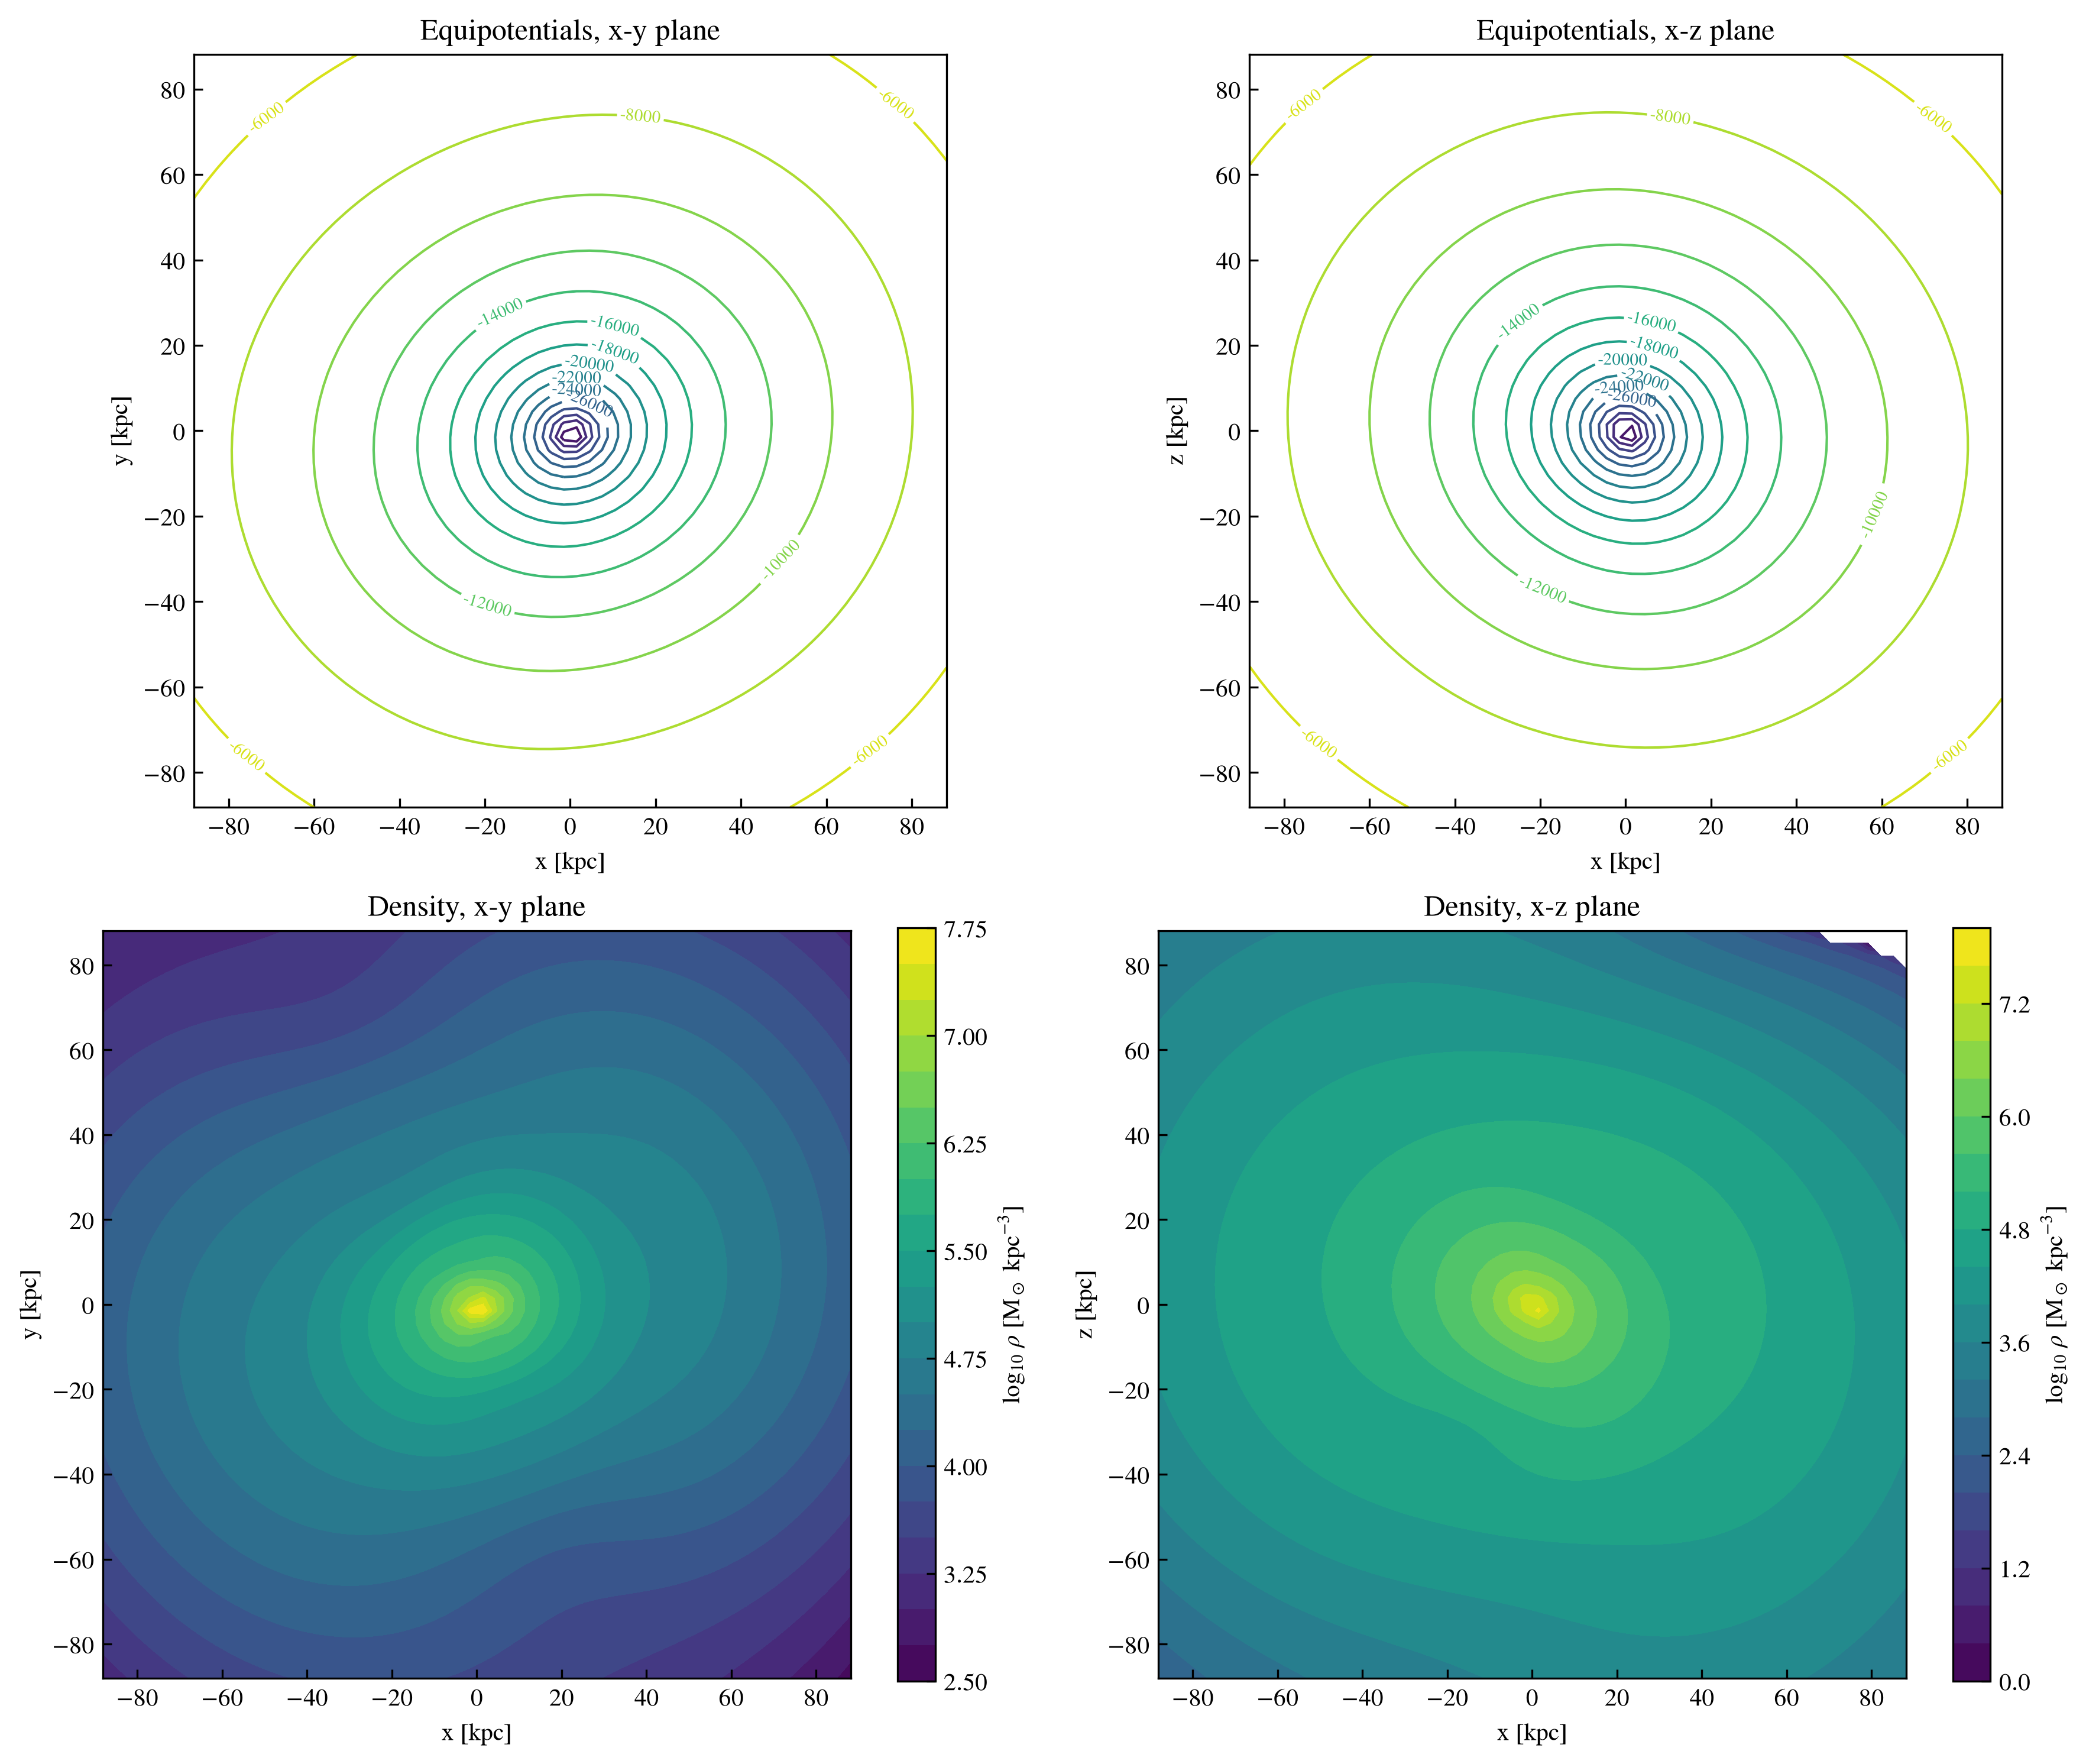

In [ ]:
a.plot_potential_density_scf_2d(pot_scf, data_path, plot=True, output=f"{OUTPUT}/halo_potential_density_scf_2d.png");

In the figures above both the density and potential of the model are shown, it's again clear that the assumption of spherical symmetry is rather faulty.

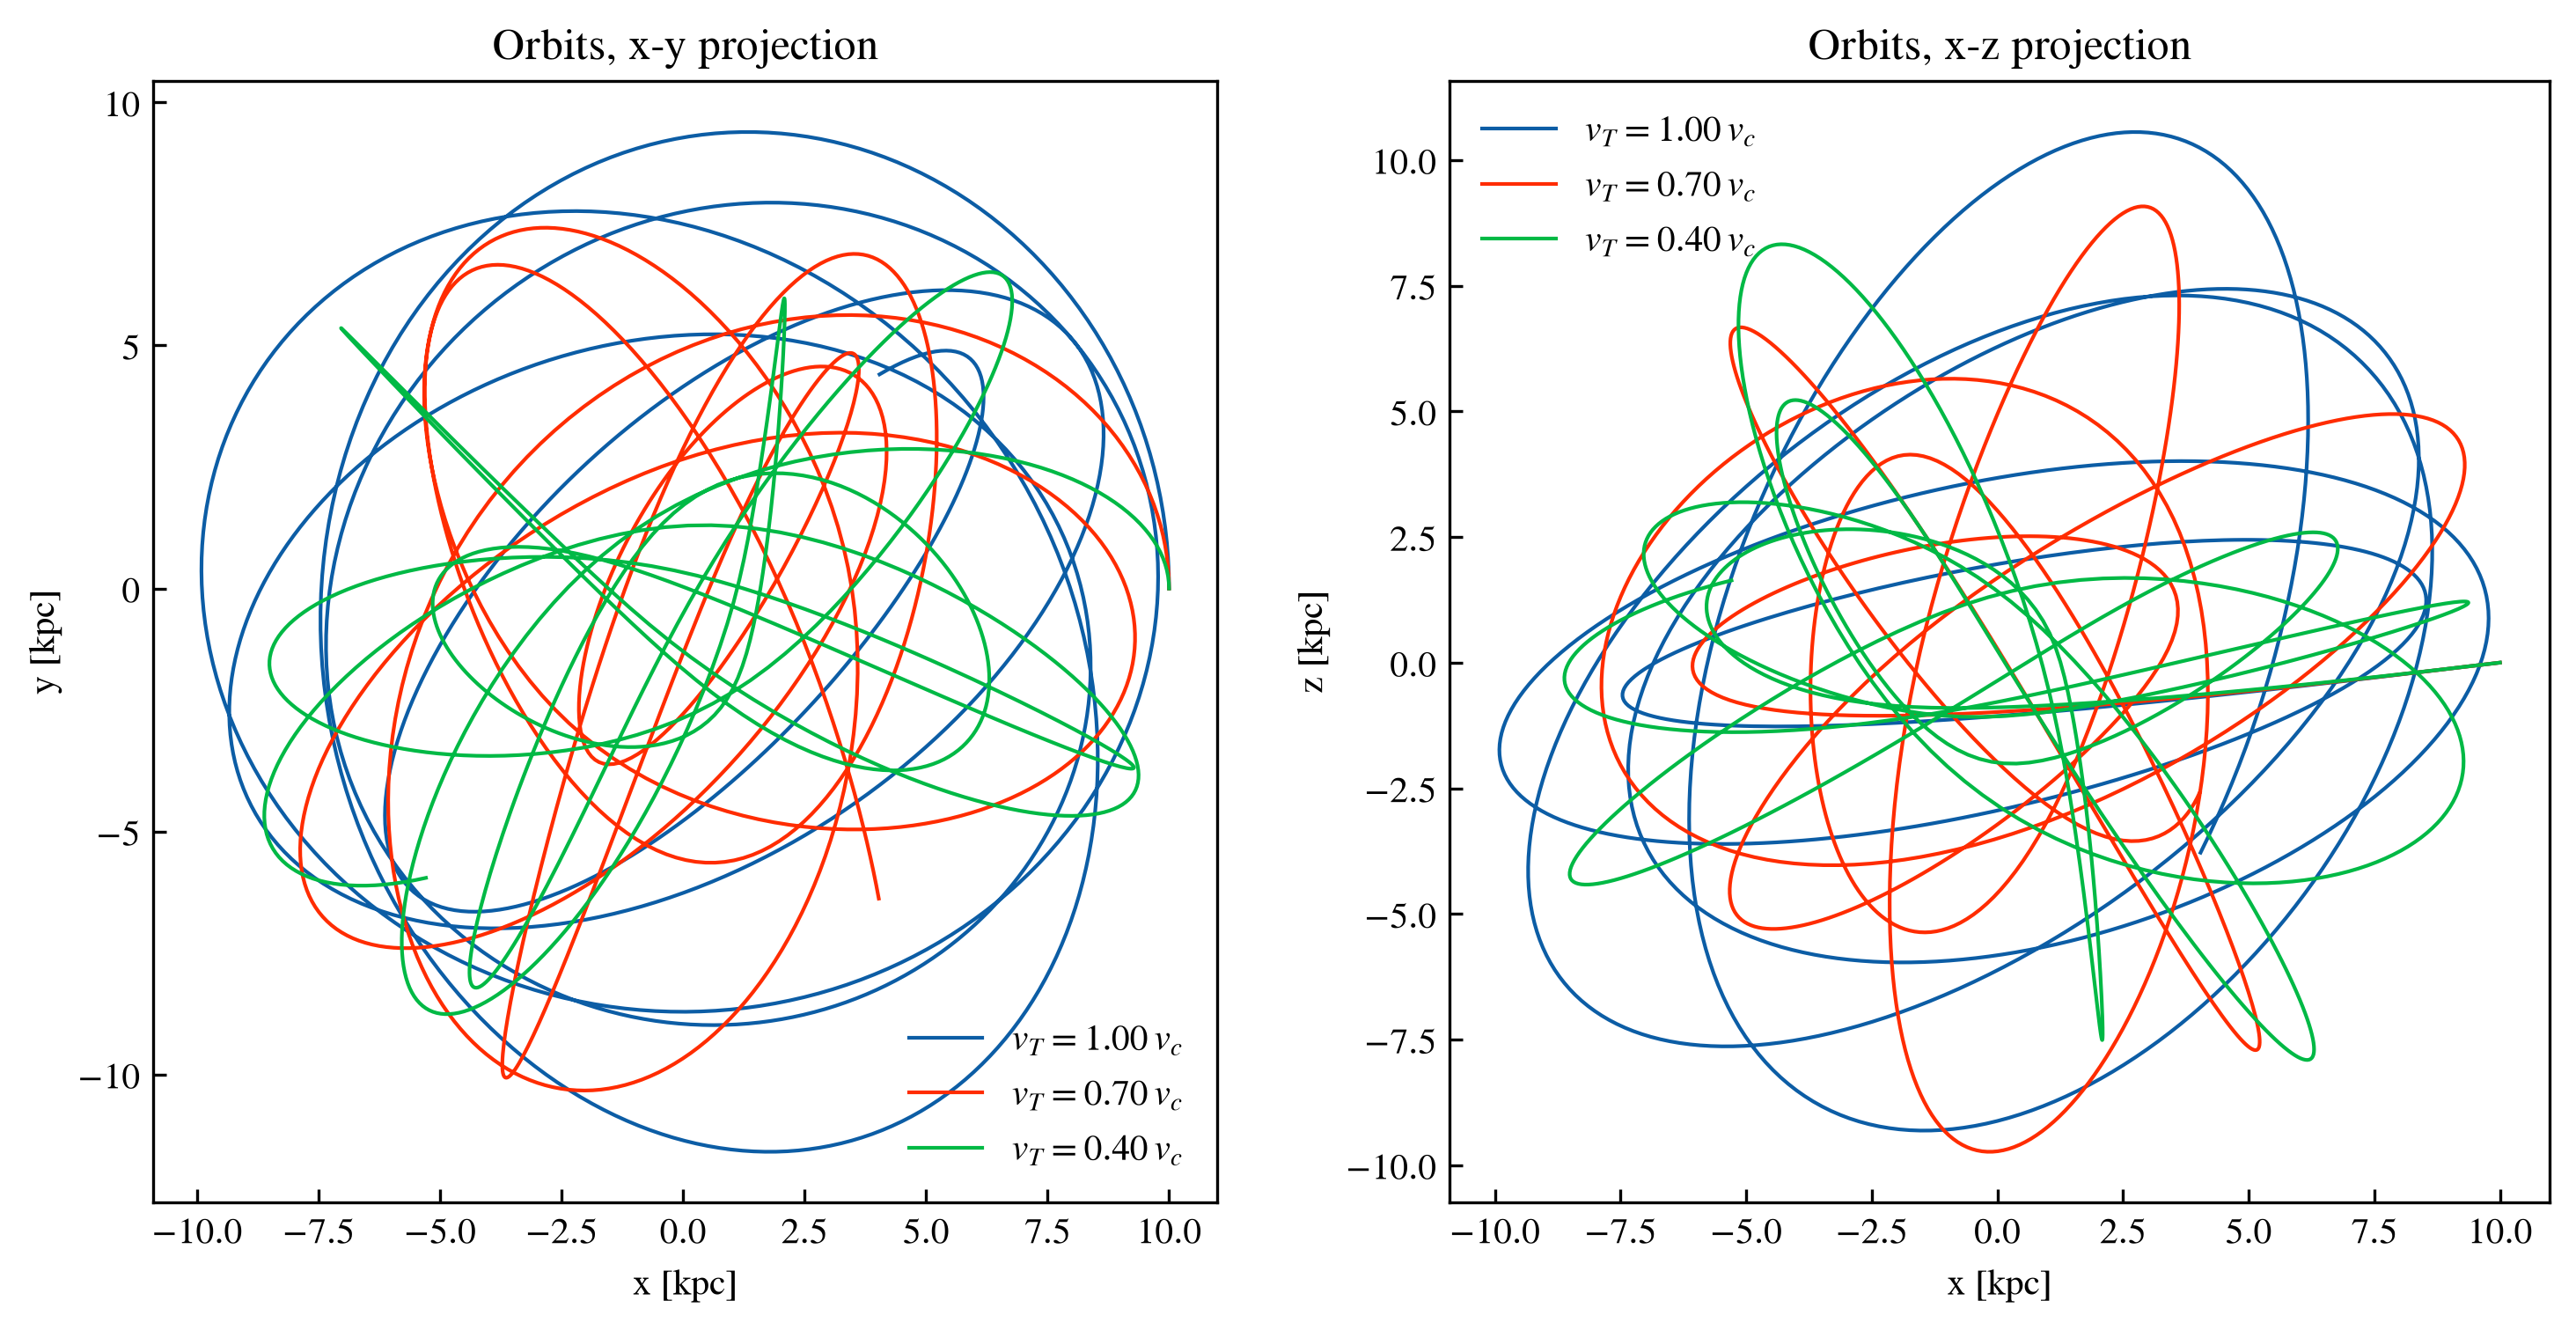

In [ ]:
a.integrate_orbits_scf(pot_scf, r0=10 * u.kpc, plot=True, output=f"{OUTPUT}/dm_orbits_scf.png");

The orbits are plotted again, it's clear that the rosettes are gone due to the assumption of spherical symmetry disappearing.

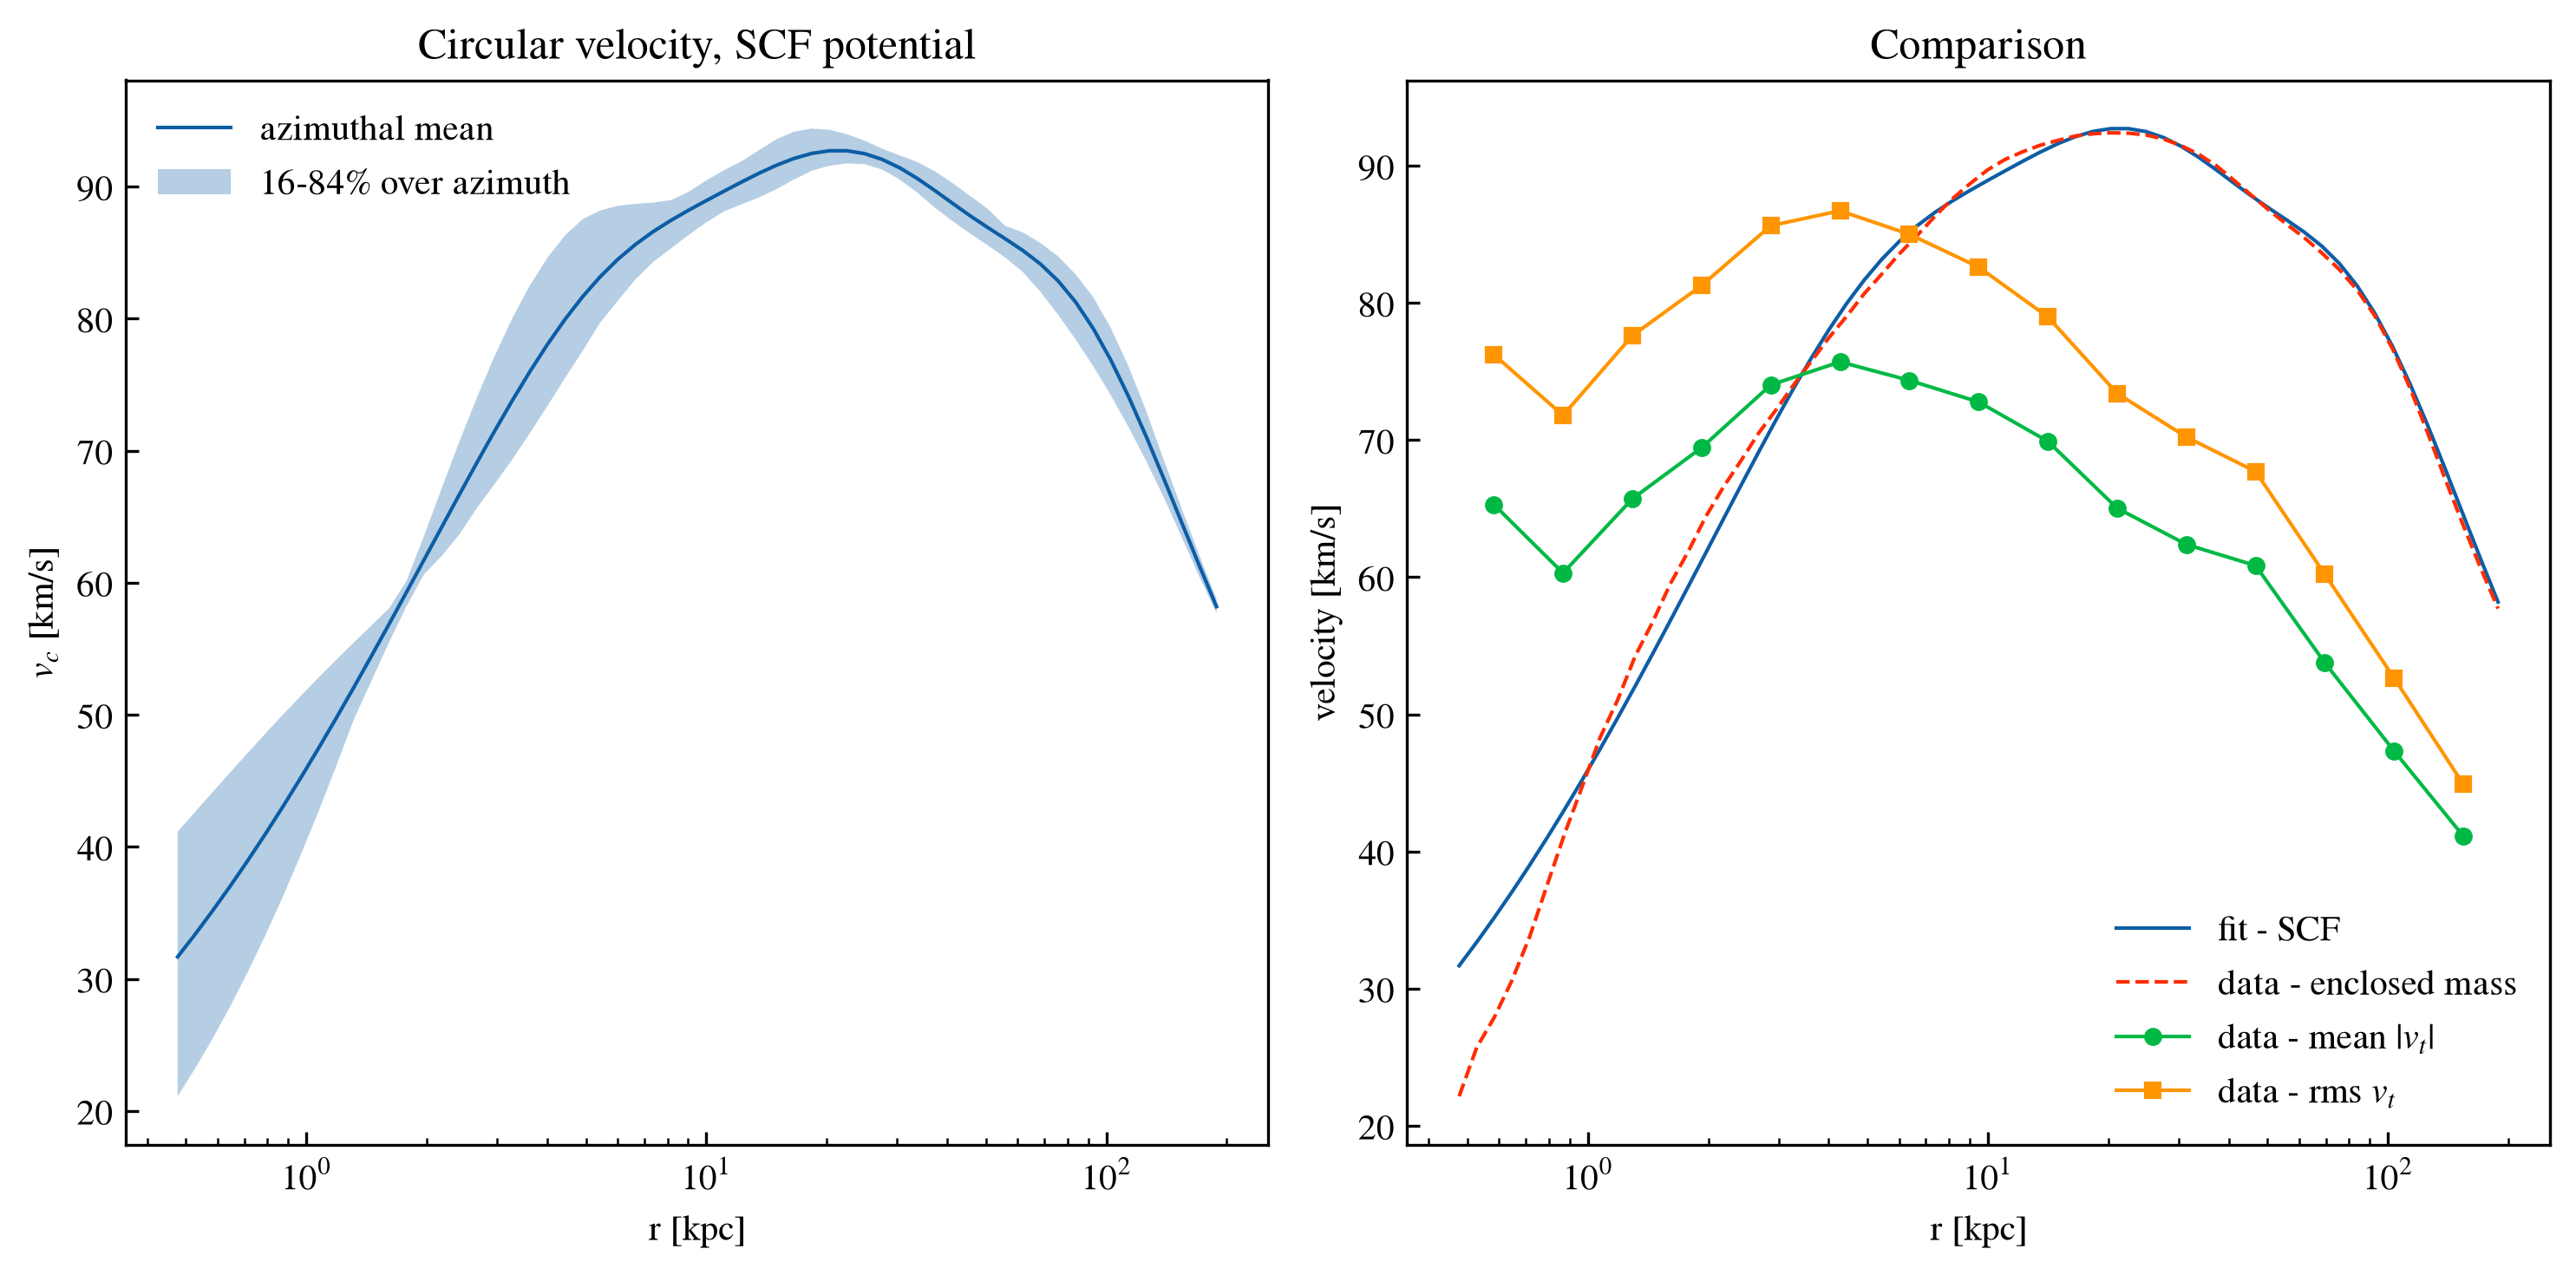

In [ ]:
a.compare_rotation_curves_scf(data_path, plot=True, output=f"{OUTPUT}/dm_circular_velocities_scf.png");

Here the rotation curve calculated in the three distinct ways can be seen again. Now it can be confirmed that the discrepancy between the Einasto and the enclosed mass circular velocity was indeed due to the faulty assumption of spherical symmetry. Again, the discrepancy between the tangential velocity and the other curves remains for the same reasons as mentioned previously.

## B: Large Scale Statistics

In [ ]:
data_path = "data/TNG50-1-Dark_subhalosCat.hdf5"
min_mass = 0.0                  # minimum subhalo mass in Msun (0 = no cut)
max_correlation_halos = 40000   # subsample size for xi(r); 0 uses all subhalos
box_size, positions, masses = b.get_subhalo_data(data_path, min_mass=min_mass)
print(f"Box size: {box_size:.2f} cMpc, {len(masses)} subhalos after selection")

Box size: 51.67 cMpc, 6616159 subhalos after selection


### Mass Function

/home/lservaes/ugent/tana/project/src/subhalo_statistics.py:192: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()

/home/lservaes/ugent/tana/project/src/subhalo_statistics.py:194: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(output)

/home/lservaes/miniforge3/envs/tana/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)

/home/lservaes/miniforge3/envs/tana/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)



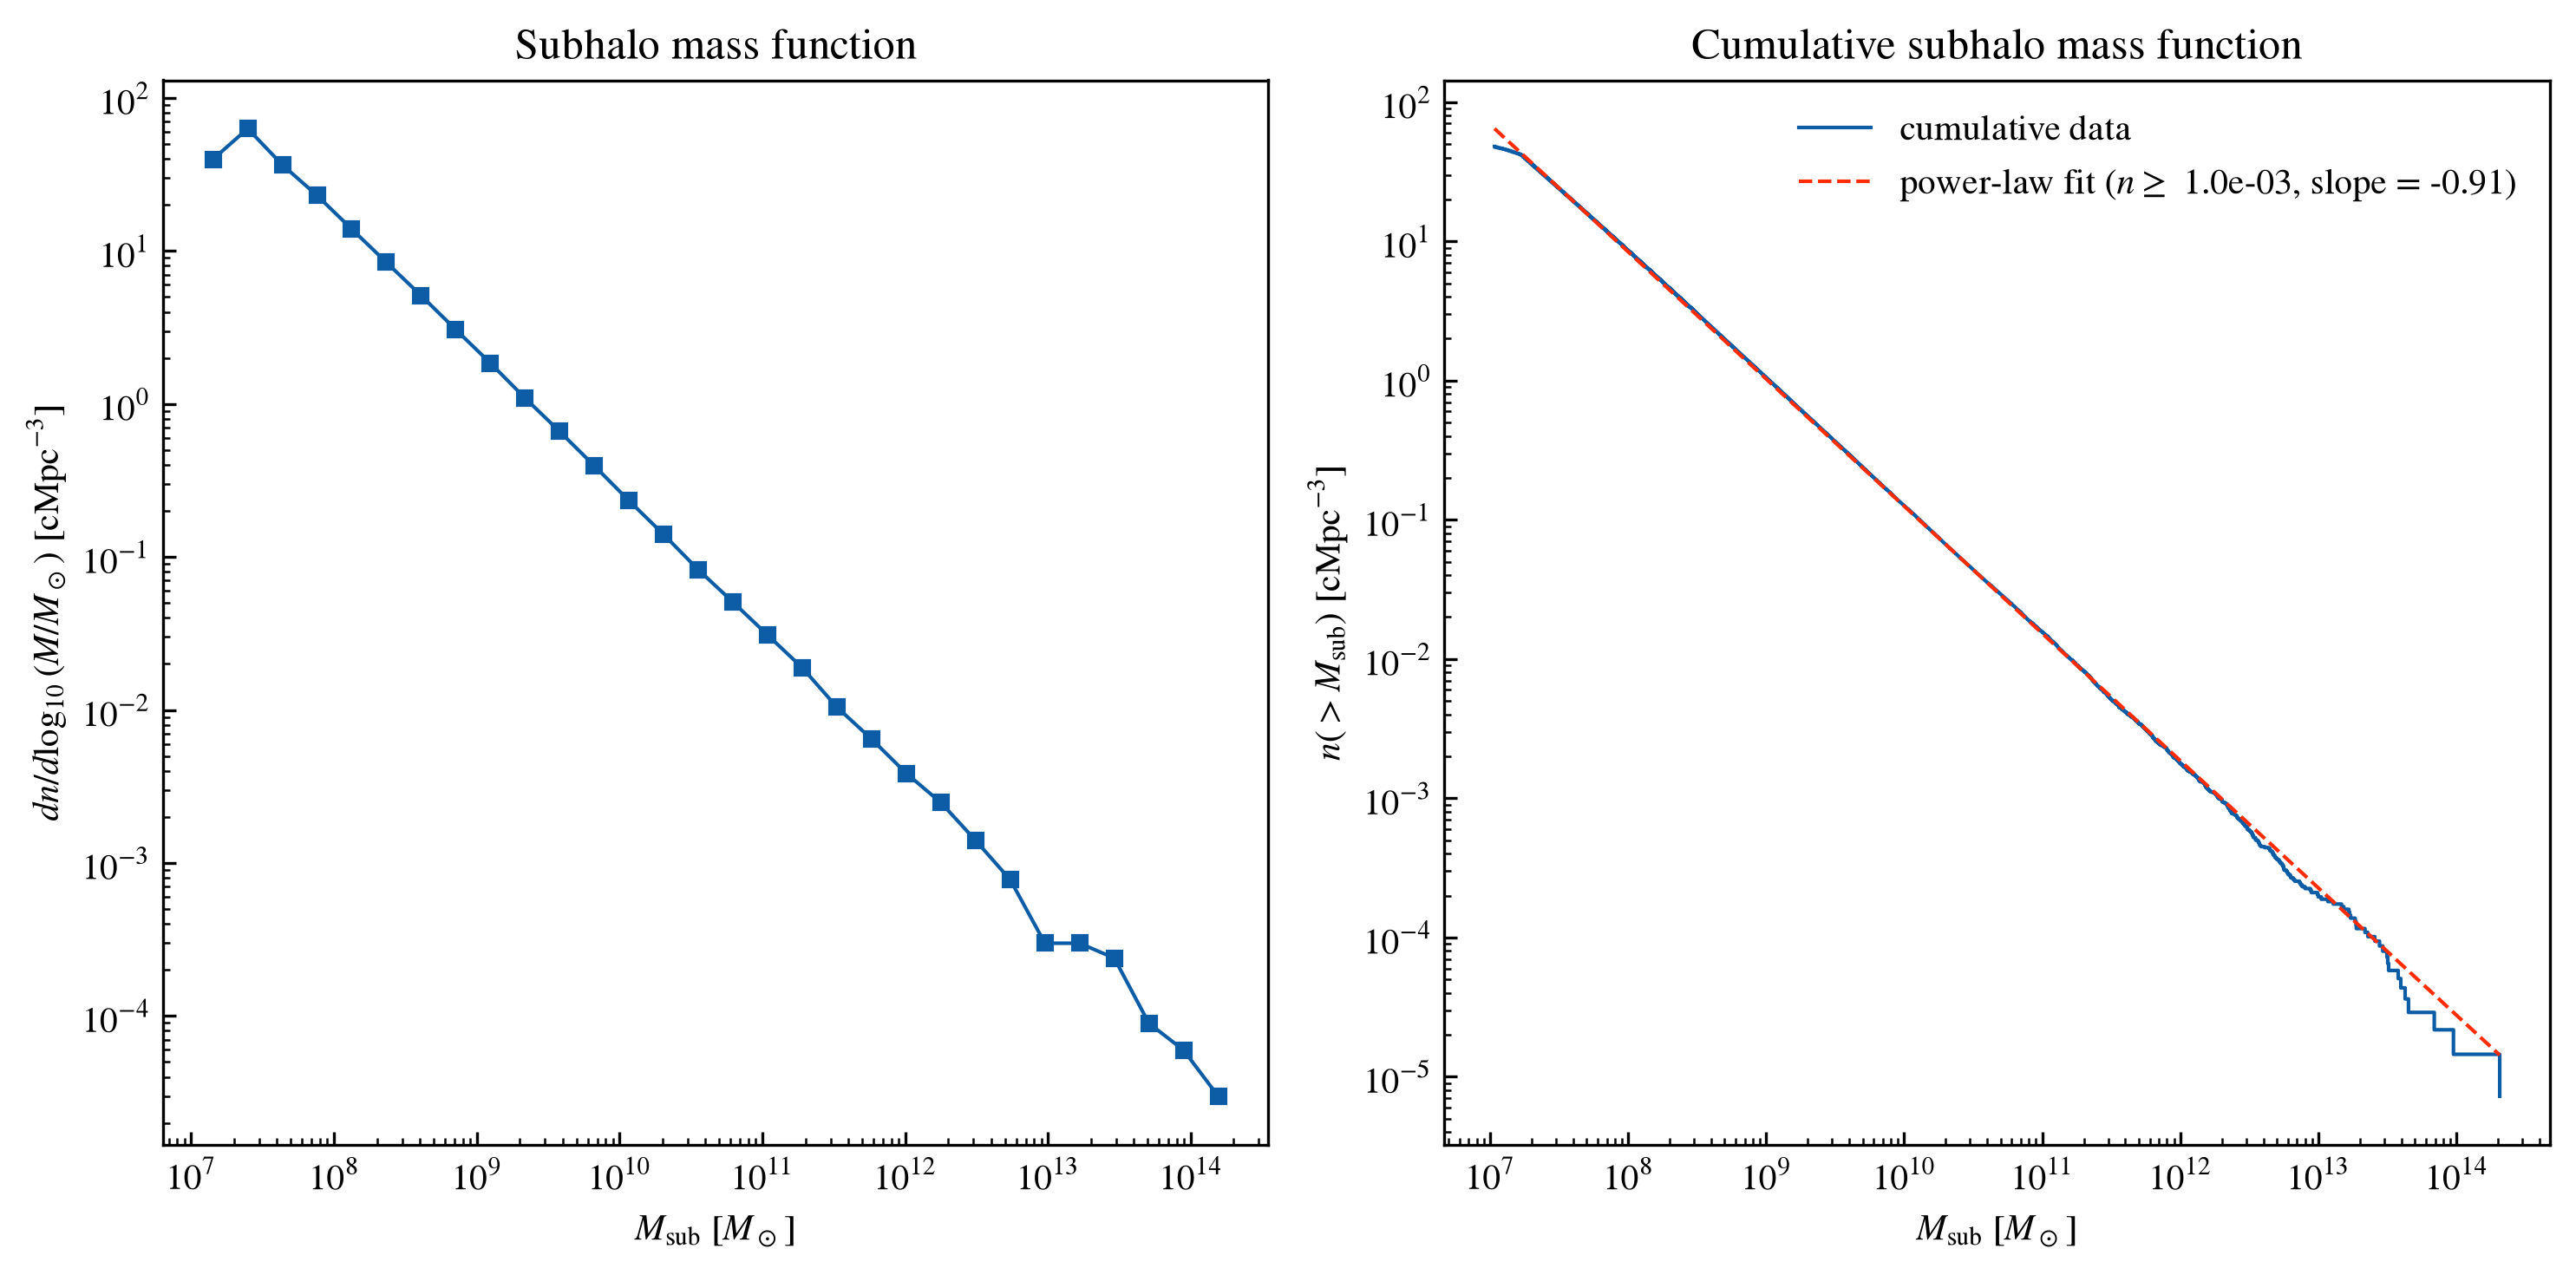

In [ ]:
b.plot_mass_function(masses, box_size, output=f"{OUTPUT}/subhalo_mass_function.png");

Something something power law -1 corresponds to literature.

### Autocorrelation Function

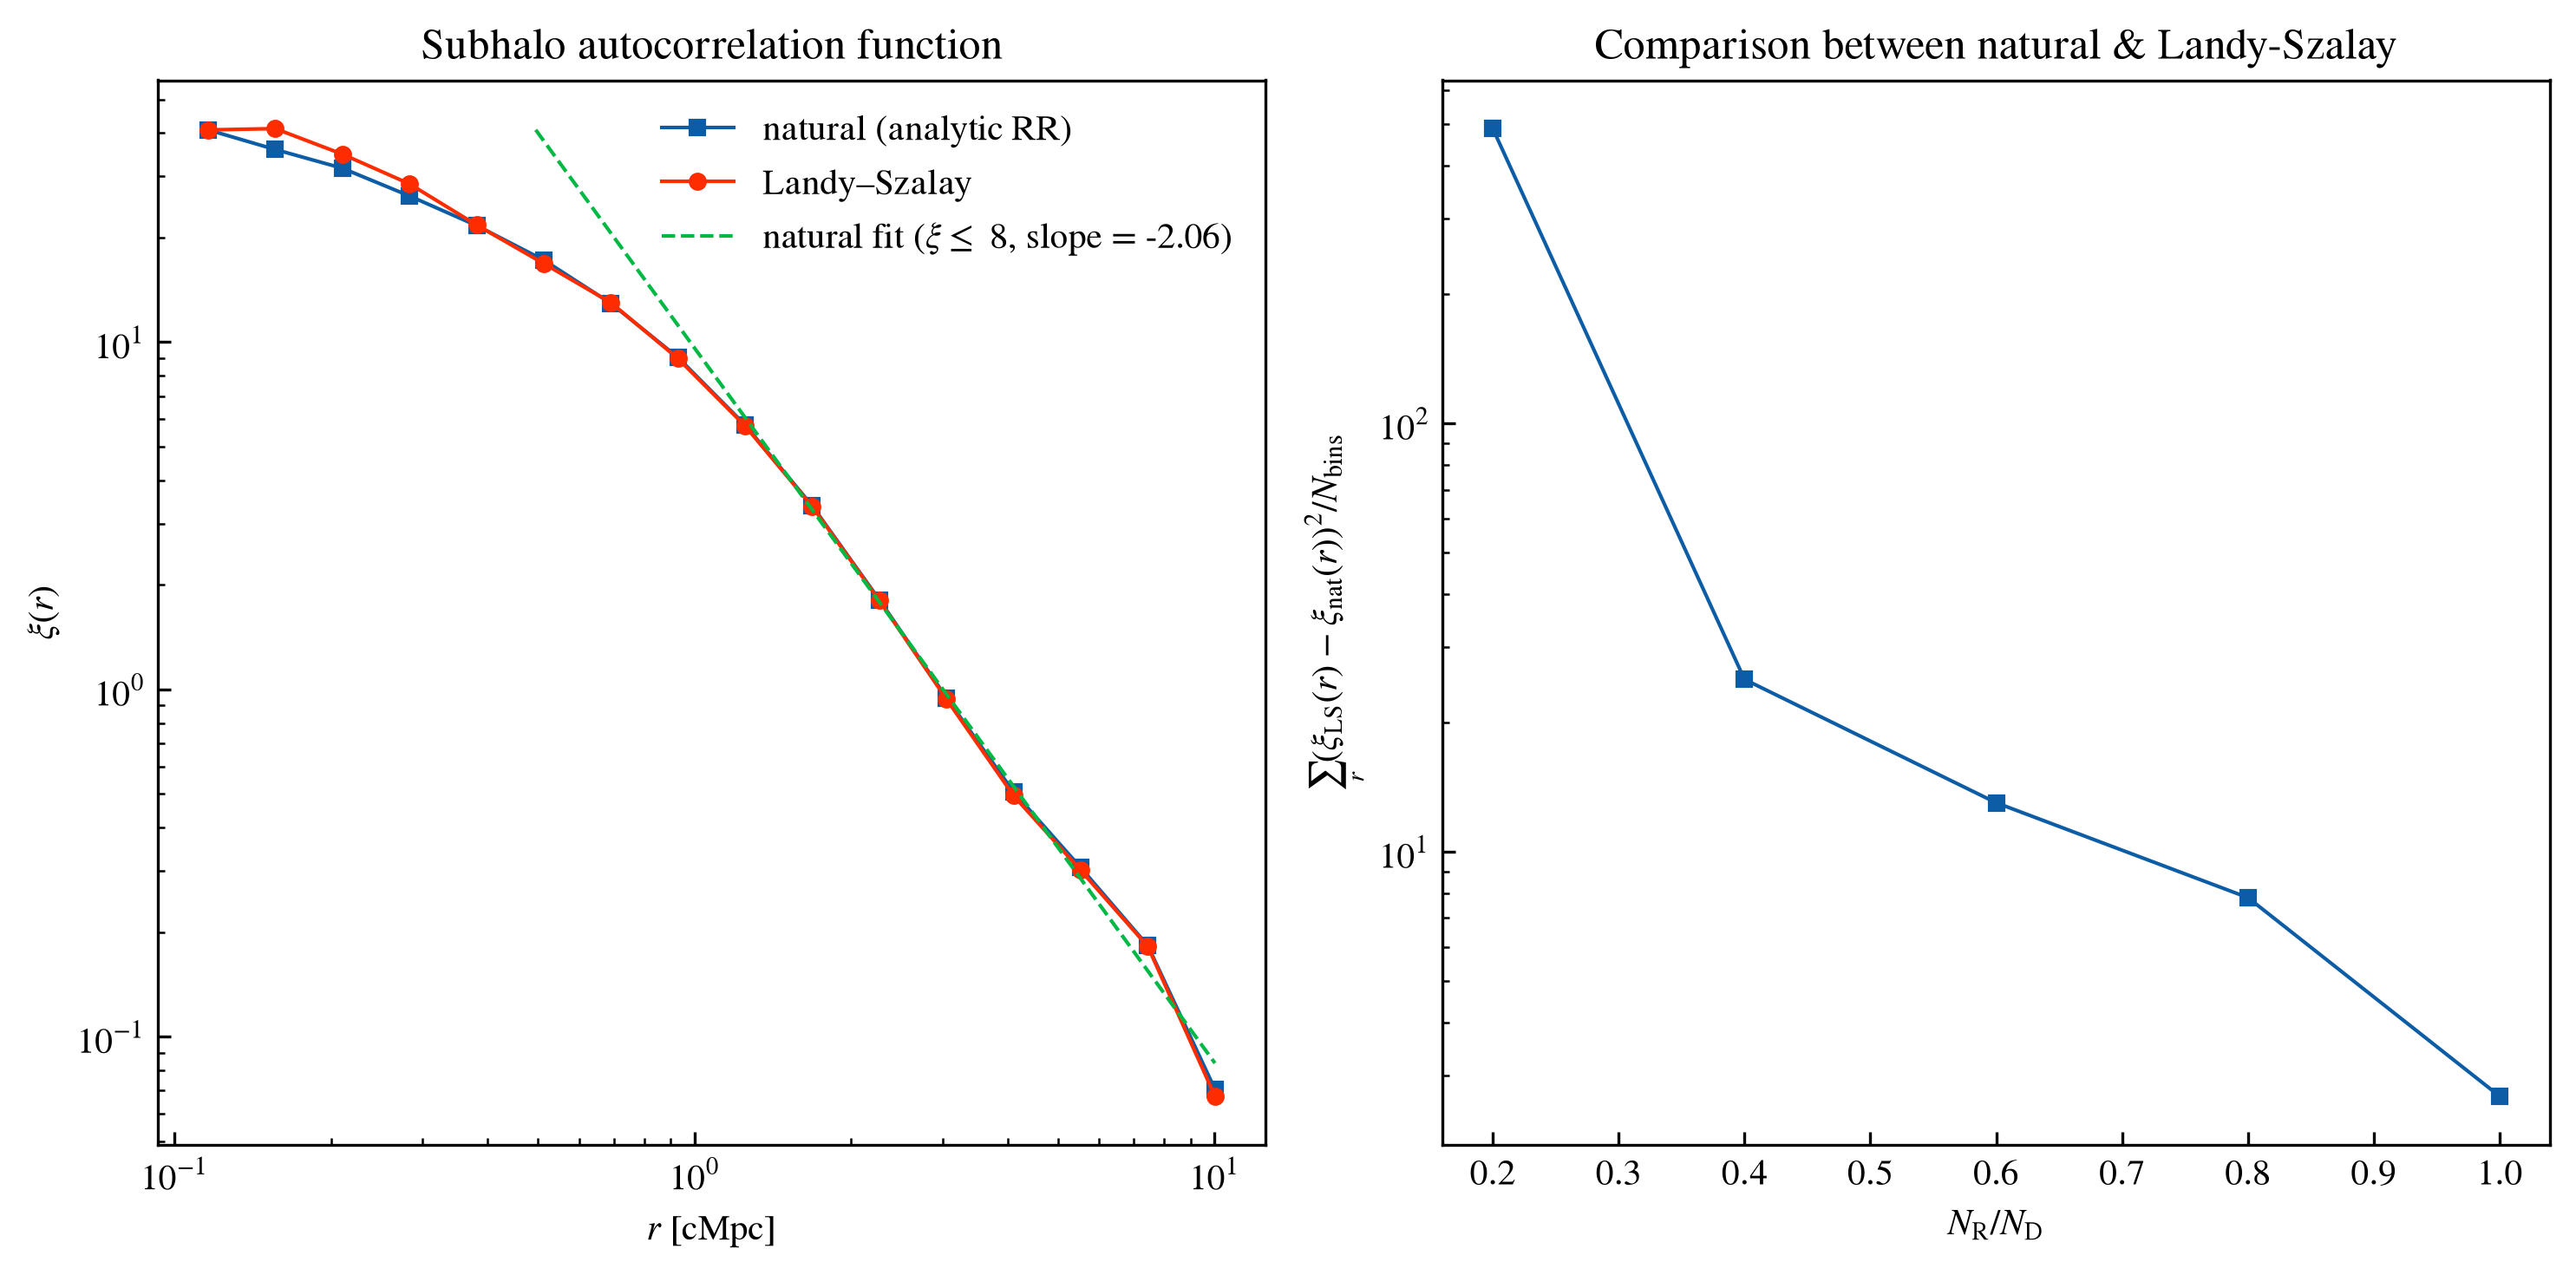

In [ ]:
positions_sample = b.sample_positions(positions, max_halos=max_correlation_halos)
b.plot_correlation_function(positions_sample, box_size, output=f"{OUTPUT}/subhalo_correlation_function.png");

The natural and Landy-Szalay (LS) estimators for the autocorrelation function are defined as:

$$\chi_\mathrm{nat}(r) = \frac{\mathrm{DD}(r)}{\mathrm{RR}(r)} - 1 \quad\quad \chi_\mathrm{LS}(r) = \frac{\mathrm{DD}(r) - 2\mathrm{DR}(r)}{\mathrm{RR}(r)} + 1$$

where $\mathrm{AB}(r)$ is the number of pairs within a distance $[r/w, wr]$ (log bins) between catalogues $\mathrm{A}$ and $\mathrm{B}$ (normalized by the total number of pairs). In practice, $D$ is a uniformly selected subset of the TNG50 subhalo catalogue, and $R$ is randomly generated. An analytical expression for $\mathrm{RR}(r)$ can be obtained by considering spherical shells between two radii $r/w, wr$. Then, the number of particles within a shell is given by the density x volume fraction of that shell, and the number of pairs is:

$$\mathrm{RR}(r) = \frac{N(N - 1)}{2} \frac{4\pi r^3}{3L^3}(w^3 - \frac{1}{w^3})$$

Since TNG50 is a periodic cosmological volume, this is valid for $r < L/2$ (and indeed $\xi(r)$ only makes sense for this range). Furthermore, $\mathrm{DR}(r) = \mathrm{RR}(r)$ and the LS estimator is reduced to the natural one.

The natural estimator was calculated using the analytical expression, while for the LS estimator a random catalogue was built. At small distances, there is a discrepancy between the two, since the pair count for the random catalogue at that distance is low. To show that this is noise of random origin, the difference between natural and LS is plotted (right) for increasing size of the random catalogue. Indeed, one observes a systematic decrease.

**Something something uniform subset....**